# 01 · Neural network fundamentals

**Goal:** understand how a neural network learns before we use big pretrained models on MVTec AD.
Everything here uses **Fashion-MNIST**: 70,000 small grayscale photos of clothing in 10 classes
(Xiao, Rasul and Vollgraf, Zalando Research, 2017; MIT licence). It is small enough to train a
network in a minute on a laptop, but hard enough that differences between methods show.

Sections:

1. Tensors, gradients and gradient descent, and a first look at Fashion-MNIST
2. A fully connected network and our own training loop
3. Overfitting on purpose, and three ways to stop it
4. A small convolutional network (CNN)
5. Data augmentation: when it helps and when it is wrong

Then one final check of the two chosen models on the test set.

The last section, *What I learned*, sums up every section and has questions to check yourself.

In [1]:
import time
from collections.abc import Callable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image, ImageOps
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import FashionMNIST

from inspection.config import load_config, project_path
from inspection.device import get_device, set_seed
from inspection.plotting import GRID, INK, INK_MUTED, INK_SECONDARY, SERIES, apply_style

config = load_config()
SEED = config["seed"]
set_seed(SEED)
DEVICE = get_device()
DATA_DIR = project_path(config["paths"]["fashion_mnist_dir"])
RESULTS_DIR = project_path(config["paths"]["results_dir"])
apply_style()
pd.set_option("display.precision", 4)

print("PyTorch", torch.__version__, "| device:", DEVICE)

PyTorch 2.15.0 | device: mps


## 1a. Tensors

A **tensor** is PyTorch's name for a grid of numbers with any number of dimensions: one number
(0 dimensions), a list (1), a table (2), or a stack of tables (3 or more). It is the same idea as
a NumPy array, with two extras: it can live on the GPU (`mps` on this Mac), and it can record the
calculations done with it, so PyTorch can compute gradients (section 1b). Every tensor has a
**shape** (the size of each dimension), a **dtype** (the number type; networks use 32-bit
floats) and a **device**. One difference from Stage 0: NumPy and PIL store an image as
height × width × channels, but PyTorch wants **channels × height × width**, with one more
dimension in front for a batch of images.

The most important calculation inside a network layer is **matrix multiplication** (`@`). Each
row of the result is a weighted sum: for the row `[1, 2, 3]` and the weights `[0.5, -1, 2]` it
is 1·0.5 + 2·(−1) + 3·2 = 4.5.

In [2]:
scalar = torch.tensor(3.0)
vector = torch.tensor([1.0, 2.0, 3.0])
matrix = torch.tensor([[1.0, 2.0, 3.0],
                       [4.0, 5.0, 6.0]])
for name, t in [("scalar", scalar), ("vector", vector), ("matrix", matrix)]:
    print(f"{name:6s}  shape={str(tuple(t.shape)):7s}  dimensions={t.ndim}  dtype={t.dtype}")

# A batch of 8 colour images of 256 x 256 pixels: the input size we chose for MVTec AD.
batch = torch.zeros(8, 3, 256, 256)
print(f"\nbatch of images: shape={tuple(batch.shape)} = {batch.numel():,} numbers")

# Stage 0 images were NumPy arrays (height, width, channels); permute reorders the dimensions.
image_hwc = np.zeros((256, 256, 3), dtype=np.uint8)
image_chw = torch.from_numpy(image_hwc).permute(2, 0, 1)
print(f"NumPy (H, W, C) {image_hwc.shape} -> PyTorch (C, H, W) {tuple(image_chw.shape)}")

weights = torch.tensor([[0.5], [-1.0], [2.0]])  # shape (3, 1)
print("\nmatrix * 2 (number by number):\n", matrix * 2)
print("matrix @ weights (one weighted sum per row):\n", matrix @ weights)

# Moving a tensor to the GPU keeps the numbers and changes where they are stored.
print("\nmatrix is now on:", matrix.to(DEVICE).device)

scalar  shape=()       dimensions=0  dtype=torch.float32
vector  shape=(3,)     dimensions=1  dtype=torch.float32
matrix  shape=(2, 3)   dimensions=2  dtype=torch.float32

batch of images: shape=(8, 3, 256, 256) = 1,572,864 numbers
NumPy (H, W, C) (256, 256, 3) -> PyTorch (C, H, W) (3, 256, 256)

matrix * 2 (number by number):
 tensor([[ 2.,  4.,  6.],
        [ 8., 10., 12.]])
matrix @ weights (one weighted sum per row):
 tensor([[4.5000],
        [9.0000]])

matrix is now on: mps:0


## 1b. Gradients: by hand and by PyTorch

Training means changing the model's numbers, its **weights**, so that its predictions get better.
We measure "how wrong" with one number, the **loss**; here the squared error
(prediction − truth)². The **gradient** of the loss with respect to a weight says how fast the
loss changes when we nudge that weight up: a gradient of −20 means "raise this weight by 0.001
and the loss drops by about 0.02". Working this out by hand for millions of weights is
impossible, so PyTorch's **autograd** records every calculation done with tensors marked
`requires_grad=True` and then walks back through them with the chain rule. That backward walk is
**backpropagation**, and `loss.backward()` starts it.

**The smallest possible example.** A model with two weights predicts ŷ = w·x + b. Start with
w = 1, b = 0, and one training example x = 2 whose true answer is y = 7.

- Prediction: ŷ = 1·2 + 0 = 2. Loss: L = (ŷ − y)² = (2 − 7)² = **25**.
- Chain rule: dL/dw = 2(ŷ − y)·x = 2·(−5)·2 = **−20**, and dL/db = 2(ŷ − y) = 2·(−5) = **−10**.

Both gradients are negative: raising w or b lowers the loss. That makes sense, because the
prediction (2) is too low. Below, three ways to get these numbers must agree.

In [3]:
x, y = 2.0, 7.0  # one training example: input and true answer


def squared_error(w: float, b: float) -> float:
    return (w * x + b - y) ** 2


# 1) By hand, with the chain-rule formulas from the text.
w, b = 1.0, 0.0
y_hat = w * x + b
by_hand = (2 * (y_hat - y) * x, 2 * (y_hat - y))

# 2) By PyTorch. requires_grad=True tells autograd to record calculations that use w and b.
w_t = torch.tensor(1.0, requires_grad=True)
b_t = torch.tensor(0.0, requires_grad=True)
loss = (w_t * x + b_t - y) ** 2
loss.backward()  # backpropagation: fills w_t.grad and b_t.grad
by_pytorch = (w_t.grad.item(), b_t.grad.item())

# 3) By nudging: move one weight a tiny step up and down and measure how the loss changes.
#    This is the definition of a gradient, and a good check that the other two are right.
h = 1e-4
by_nudging = (
    (squared_error(w + h, b) - squared_error(w - h, b)) / (2 * h),
    (squared_error(w, b + h) - squared_error(w, b - h)) / (2 * h),
)

print(f"loss = {loss.item():.0f}")
pd.DataFrame([by_hand, by_pytorch, by_nudging], columns=["dL/dw", "dL/db"],
             index=["by hand", "by PyTorch (autograd)", "by nudging"])

loss = 25


,dL/dw,dL/db
by hand,-20.0,-10.0
by PyTorch (autograd),-20.0,-10.0
by nudging,-20.0,-10.0


## 1c. Gradient descent: learning from the gradient

The gradient points in the direction that makes the loss **bigger**, so we step the other way:
w ← w − learning rate × gradient. The **learning rate** sets the step size. Too small, and
learning is slow; too large, and each step overshoots the best value, so the loss can grow
instead of shrink. Repeating this step many times is **gradient descent**, and an **optimizer**
(here `torch.optim.SGD`) is the PyTorch object that applies the update to every weight.

With the example above and learning rate 0.01: w becomes 1 − 0.01·(−20) = 1.2 and b becomes
0 − 0.01·(−10) = 0.1. The prediction becomes 2.5 and the loss drops from 25 to 20.25.

Below, the model learns a line from 100 noisy points. The loop has five steps, and **every
training loop in this project has the same five**: forward pass, loss, clear old gradients,
backward pass, update.

In [4]:
# 100 noisy points around the line y = 3x + 2. The model does not know 3 and 2; it must learn them.
generator = torch.Generator().manual_seed(SEED)
x_line = torch.rand(100, generator=generator) * 2 - 1  # 100 values between -1 and 1
y_line = 3 * x_line + 2 + 0.3 * torch.randn(100, generator=generator)


def fit_line(lr: float, steps: int) -> tuple[float, float, list[float]]:
    """Learn w and b by gradient descent; return them and the loss after every step."""
    w = torch.zeros(1, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    optimizer = torch.optim.SGD([w, b], lr=lr)
    losses = []
    for _ in range(steps):
        y_hat = w * x_line + b                  # 1. forward pass: predict every point
        loss = ((y_hat - y_line) ** 2).mean()   # 2. loss: mean squared error
        optimizer.zero_grad()                   # 3. clear old gradients (PyTorch adds them up)
        loss.backward()                         # 4. backward pass: new gradients
        optimizer.step()                        # 5. update: w <- w - lr * gradient
        losses.append(loss.item())
    return w.item(), b.item(), losses


w_fit, b_fit, _ = fit_line(lr=0.1, steps=200)
print(f"gradient descent (lr 0.1, 200 steps): w = {w_fit:.3f}, b = {b_fit:.3f}   (true line: 3 and 2)")

# For a straight line there is also an exact formula for the best fit (least squares).
X = torch.stack([x_line, torch.ones_like(x_line)], dim=1)  # one column for w, one for b
w_best, b_best = torch.linalg.lstsq(X, y_line[:, None]).solution.flatten().tolist()
best_loss = ((w_best * x_line + b_best - y_line) ** 2).mean().item()
print(f"exact best line (least squares):      w = {w_best:.3f}, b = {b_best:.3f}, loss {best_loss:.3f}\n")

# Same data, three learning rates.
LEARNING_RATES = (0.01, 0.1, 1.05)
STEPS = 60
runs = {lr: fit_line(lr, STEPS)[2] for lr in LEARNING_RATES}
for lr, losses in runs.items():
    print(f"learning rate {lr:<5}: loss after 1 step {losses[0]:8.3f}, after {STEPS} steps {losses[-1]:12.3f}")

gradient descent (lr 0.1, 200 steps): w = 2.931, b = 2.000   (true line: 3 and 2)
exact best line (least squares):      w = 2.931, b = 2.000, loss 0.060

learning rate 0.01 : loss after 1 step    7.390, after 60 steps        1.701
learning rate 0.1  : loss after 1 step    7.390, after 60 steps        0.060
learning rate 1.05 : loss after 1 step    7.390, after 60 steps   494709.562


The learned line is not exactly y = 3x + 2, because the noise moves the points a little. But
gradient descent found the same line as the exact formula: the best any line can do on these
100 points. Its loss is not 0, because the noise is random and no line can predict it. For a
neural network there is no exact formula, which is why we train it with gradient descent.

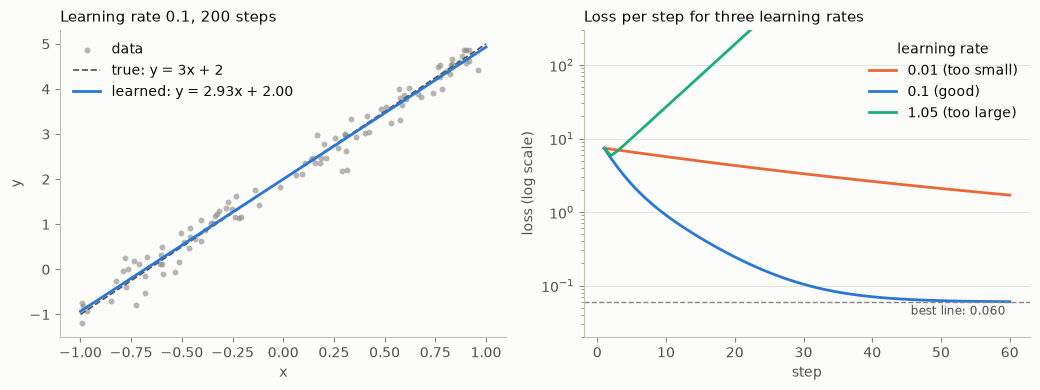

In [5]:
fig, (ax_data, ax_loss) = plt.subplots(1, 2, figsize=(10.5, 4))

grid_x = torch.linspace(-1, 1, 2)
ax_data.scatter(x_line, y_line, s=18, color=INK_MUTED, alpha=0.6, linewidths=0, label="data")
ax_data.plot(grid_x, 3 * grid_x + 2, color=INK_SECONDARY, lw=1.2, ls="--", label="true: y = 3x + 2")
ax_data.plot(grid_x, w_fit * grid_x + b_fit, color=SERIES[0], lw=2,
             label=f"learned: y = {w_fit:.2f}x + {b_fit:.2f}")
ax_data.set_xlabel("x")
ax_data.set_ylabel("y")
ax_data.set_title("Learning rate 0.1, 200 steps", loc="left")
ax_data.legend(loc="upper left")

# Colour follows the run: learning rate 0.1 is blue here and in the left panel; any other
# learning rate takes the next colour in order.
notes = {0.01: " (too small)", 0.1: " (good)", 1.05: " (too large)"}
other_colours = iter(SERIES[1:])
for lr, losses in runs.items():
    colour = SERIES[0] if lr == 0.1 else next(other_colours)
    ax_loss.plot(range(1, len(losses) + 1), losses, color=colour, lw=2,
                 label=f"{lr}{notes.get(lr, '')}")
ax_loss.axhline(best_loss, color=INK_MUTED, lw=1, ls="--")
ax_loss.text(STEPS, best_loss * 0.92, f"best line: {best_loss:.3f} ", ha="right", va="top",
             fontsize=8.5, color=INK_SECONDARY)
ax_loss.set_yscale("log")
ax_loss.set_ylim(0.02, 300)
ax_loss.set_xlabel("step")
ax_loss.set_ylabel("loss (log scale)")
ax_loss.set_title("Loss per step for three learning rates", loc="left")
ax_loss.grid(axis="y")
ax_loss.set_axisbelow(True)
ax_loss.legend(title="learning rate", loc="upper right")
fig.tight_layout()
plt.show()

## 1d. A first look at Fashion-MNIST

Fashion-MNIST has 60,000 training and 10,000 test images, each 28 × 28 pixels, grayscale, with
one of 10 labels. We take 10,000 of the 60,000 training images away as a **validation set**. The
model never trains on it; we use it to make choices, such as when to stop training. The test set
is used once, at the very end. This is the same rule as for MVTec AD: whatever we use to make
choices cannot also tell us honestly how good the final model is.

The split is random but fixed by the seed, so every run uses the same 50,000 / 10,000 images.

In [6]:
train_full = FashionMNIST(DATA_DIR, train=True, download=True)  # downloads ~30 MB the first time
test_set = FashionMNIST(DATA_DIR, train=False, download=True)
CLASSES = train_full.classes

# Fixed random split of the 60,000 training images: 50,000 train, 10,000 validation.
order = torch.randperm(len(train_full), generator=torch.Generator().manual_seed(SEED))
val_idx, train_idx = order[:10_000], order[10_000:]

labels = train_full.targets
split_counts = pd.DataFrame({
    "train": torch.bincount(labels[train_idx], minlength=10).numpy(),
    "validation": torch.bincount(labels[val_idx], minlength=10).numpy(),
    "test": torch.bincount(test_set.targets, minlength=10).numpy(),
}, index=pd.Index(CLASSES, name="class"))
split_counts.loc["total"] = split_counts.sum()
split_counts.to_csv(RESULTS_DIR / "stage1_fashion_split.csv")
split_counts

,train,validation,test
class,,,
T-shirt/top,5020,980,1000
Trouser,5021,979,1000
Pullover,4939,1061,1000
Dress,5026,974,1000
Coat,4954,1046,1000
Sandal,4945,1055,1000
Shirt,5016,984,1000
Sneaker,5007,993,1000
Bag,5043,957,1000


Every class has about the same number of images in every split, so a model that always guesses
one class would be right only 10% of the time. That is the floor any model must beat.

An image is a 28 × 28 grid of numbers from 0 (black background) to 255 (white). Below, the
pixel values in the middle of the first training image, and the image itself.

shape (28, 28), dtype torch.uint8, values 0 to 255, label 9 = Ankle boot
rows 10-15, columns 10-15:
tensor([[  0,   0,   0, 193, 228, 218],
        [  3,   0,  12, 219, 220, 212],
        [  6,   0,  99, 244, 222, 220],
        [  0,   0,  55, 236, 228, 230],
        [  0,   0, 237, 226, 217, 223],
        [145, 204, 228, 207, 213, 221]], dtype=torch.uint8)


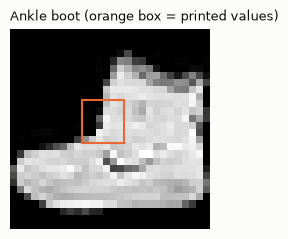

In [7]:
image, label = train_full.data[0], train_full.targets[0].item()
print(f"shape {tuple(image.shape)}, dtype {image.dtype}, values {image.min().item()} to {image.max().item()}, "
      f"label {label} = {CLASSES[label]}")
print("rows 10-15, columns 10-15:")
print(image[10:16, 10:16])

fig, ax = plt.subplots(figsize=(2.6, 2.6))
ax.imshow(image, cmap="gray", vmin=0, vmax=255)
ax.add_patch(plt.Rectangle((9.5, 9.5), 6, 6, fill=False, ec=SERIES[1], lw=1.5))
ax.set_title(f"{CLASSES[label]} (orange box = printed values)", fontsize=9, loc="left")
ax.axis("off")
plt.show()

Ten random training images per class. Some classes are easy to tell apart (trouser, bag), others
look alike even to us (T-shirt/top, shirt, pullover, coat). Expect the model's mistakes there.

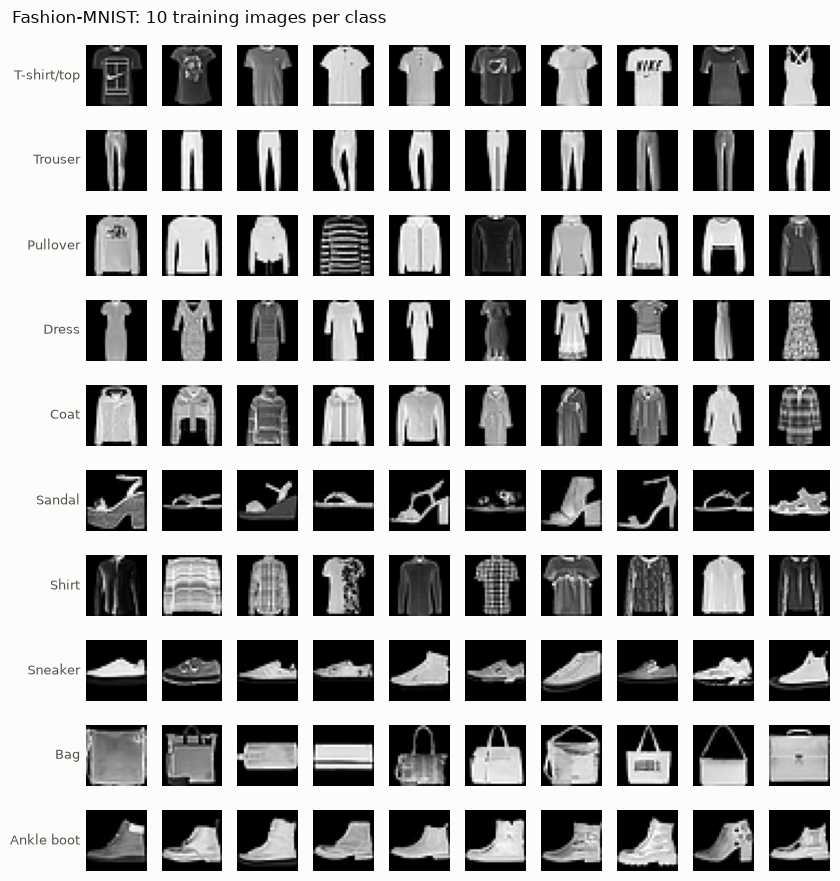

In [8]:
PER_CLASS = 10
rng = np.random.default_rng(SEED)
train_labels = labels[train_idx].numpy()

fig, axes = plt.subplots(10, PER_CLASS, figsize=(PER_CLASS * 0.85, 10 * 0.9))
for c, class_name in enumerate(CLASSES):
    picks = rng.choice(train_idx.numpy()[train_labels == c], PER_CLASS, replace=False)
    for ax, i in zip(axes[c], picks):
        ax.imshow(train_full.data[i], cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
    axes[c, 0].set_ylabel(class_name, rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle("Fashion-MNIST: 10 training images per class", x=0.02, ha="left")
fig.tight_layout()
plt.show()

## 2. A fully connected network

Now a real classifier: the network sees a 28 × 28 image and must say which of the 10 classes it
is. We build it in four steps: prepare the data, define the model, choose the loss, train it with
our own loop. Then we read the training curves and look at the mistakes.

### 2a. Preparing the data: scaling and mini-batches

Networks learn best when the input numbers are small and centred around 0. So we divide the
pixels by 255 (now 0 to 1), then subtract the mean and divide by the standard deviation. We
compute that mean and standard deviation on the **training images only**: if the validation
images helped set the scaling, a little information about them would leak into training.

A gradient computed on all 50,000 images is exact but slow, and gives only one update per pass
through the data. Instead each update uses a **mini-batch** of 128 random images: the gradient is
a bit noisy, but we get 391 updates per pass instead of 1. One pass through all training images
is an **epoch**. A PyTorch **DataLoader** cuts the data into mini-batches and shuffles it again
every epoch, so the batches are different each time.

In [9]:
# Mean and standard deviation of the training pixels only (0-1 scale).
train_pixels = train_full.data[train_idx].float() / 255
PIXEL_MEAN, PIXEL_STD = train_pixels.mean().item(), train_pixels.std().item()


def to_model_input(images: torch.Tensor) -> torch.Tensor:
    """uint8 images (N, 28, 28) -> scaled floats (N, 1, 28, 28). The 1 is the channel: grayscale."""
    x = images.float() / 255
    return ((x - PIXEL_MEAN) / PIXEL_STD).unsqueeze(1)


X_train, y_train = to_model_input(train_full.data[train_idx]), train_full.targets[train_idx]
X_val, y_val = to_model_input(train_full.data[val_idx]), train_full.targets[val_idx]
print(f"training pixels (0-1 scale): mean {PIXEL_MEAN:.4f}, std {PIXEL_STD:.4f}")
print(f"after scaling:               mean {X_train.mean():.4f}, std {X_train.std():.4f}")

BATCH_SIZE = 128


def make_loader(x: torch.Tensor, y: torch.Tensor, shuffle: bool, seed: int = SEED) -> DataLoader:
    """Mini-batches of (images, labels). A seeded generator makes the shuffling repeatable."""
    generator = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(TensorDataset(x, y), batch_size=BATCH_SIZE, shuffle=shuffle, generator=generator)


val_loader = make_loader(X_val, y_val, shuffle=False)
example_images, example_labels = next(iter(make_loader(X_train, y_train, shuffle=True)))
print(f"\none mini-batch: images {tuple(example_images.shape)}, labels {tuple(example_labels.shape)}")
print(f"mini-batches per epoch: {len(make_loader(X_train, y_train, shuffle=True))}")

training pixels (0-1 scale): mean 0.2859, std 0.3529
after scaling:               mean -0.0000, std 1.0000

one mini-batch: images (128, 1, 28, 28), labels (128,)
mini-batches per epoch: 391


### 2b. The model: layers and activations

A **linear layer** (`nn.Linear`) is the matrix multiplication from 1a plus a bias: every output
is a weighted sum of all inputs, and training learns the weights. It is called *fully connected*
because every input is connected to every output. Stacking only linear layers would be pointless:
a linear function of a linear function is still linear, so ten such layers can do no more than
one. An **activation function** between the layers bends the result. We use **ReLU**, which keeps
positive numbers and turns negative ones into 0: ReLU(−2) = 0, ReLU(3) = 3.

In PyTorch a model is a class that inherits from `nn.Module`: `__init__` creates the layers and
`forward` says how data flows through them. Ours flattens the 28 × 28 image into 784 numbers,
passes them through two hidden layers of 256 units, and ends with 10 numbers, one score per
class. These raw scores are called **logits**.

In [10]:
class FullyConnected(nn.Module):
    """Image -> 784 numbers -> 256 -> 256 -> 10 class scores (logits)."""

    def __init__(self, hidden: int = 256) -> None:
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),                # (N, 1, 28, 28) -> (N, 784): the image as one long row
            nn.Linear(28 * 28, hidden),  # hidden layer 1
            nn.ReLU(),
            nn.Linear(hidden, hidden),   # hidden layer 2
            nn.ReLU(),
            nn.Linear(hidden, 10),       # output layer: one score per class
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(x)


def parameter_table(model: nn.Module) -> pd.DataFrame:
    """One row per weight tensor: its shape and how many numbers training must learn."""
    rows = [{"parameter": name, "shape": tuple(p.shape), "count": p.numel()}
            for name, p in model.named_parameters()]
    table = pd.DataFrame(rows).set_index("parameter")
    table.loc["total"] = ["", table["count"].sum()]
    return table


set_seed(SEED)
print(FullyConnected())
parameter_table(FullyConnected())

FullyConnected(
  (layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)


,shape,count
parameter,,
layers.1.weight,"(256, 784)",200704
layers.1.bias,"(256,)",256
layers.3.weight,"(256, 256)",65536
layers.3.bias,"(256,)",256
layers.5.weight,"(10, 256)",2560
layers.5.bias,"(10,)",10
total,,269322


The weights of the first layer have shape (256, 784): one row of 784 weights for each of the 256
units. With the 256 biases that is 784 × 256 + 256 = **200,960** numbers, three quarters of the
whole model. Every pixel is connected to every unit, which is why fully connected networks get
big quickly on larger images.

An untrained model already gives an answer; it is just random. Its 10 logits for one image:

In [11]:
set_seed(SEED)
untrained = FullyConnected()
logits = untrained(example_images)  # forward pass on one mini-batch of 128 images
print("logits:", tuple(logits.shape), "= 128 images x 10 class scores")
print("first image:", logits[0].detach().numpy().round(3))

logits: (128, 10) = 128 images x 10 class scores
first image: [-0.033  0.106 -0.034 -0.213  0.058 -0.137  0.103 -0.022  0.052 -0.066]


### 2c. The loss: cross-entropy

The 10 logits can be any numbers. **Softmax** turns them into probabilities: it makes every
number positive (eˣ) and divides by the sum, so the 10 values add up to 1. **Cross-entropy
loss** then looks only at the probability the model gave to the *true* class and takes −log of
it. Probability 0.9 gives a loss of 0.11, 0.5 gives 0.69, 0.1 gives 2.30, and a confident wrong
answer (0.01) gives 4.61, so confident mistakes are punished hardest.

A useful check: an untrained model gives every class about the same probability, 1/10, so its
loss should start near −log(0.1) = **2.30**. If it starts far from that, something is wired
wrong. `nn.CrossEntropyLoss` takes the logits directly and does the softmax itself.

In [12]:
loss_fn = nn.CrossEntropyLoss()

print("probability of the true class -> loss")
for p in (0.9, 0.5, 0.1, 0.01):
    print(f"  {p:<5} -> -log({p}) = {-np.log(p):.2f}")

probabilities = torch.softmax(logits, dim=1)
print("\nuntrained model, first image, probabilities:", probabilities[0].detach().numpy().round(3))
print(f"sum of the 10 probabilities: {probabilities[0].sum().item():.3f}")

# The same loss by hand (softmax, pick the true class, -log, average) and by PyTorch.
by_hand = -torch.log(probabilities[torch.arange(len(example_labels)), example_labels]).mean()
print(f"\nloss on this mini-batch: by hand {by_hand.item():.4f}, "
      f"by nn.CrossEntropyLoss {loss_fn(logits, example_labels).item():.4f}, "
      f"expected about {-np.log(0.1):.4f}")

probability of the true class -> loss
  0.9   -> -log(0.9) = 0.11
  0.5   -> -log(0.5) = 0.69
  0.1   -> -log(0.1) = 2.30
  0.01  -> -log(0.01) = 4.61

untrained model, first image, probabilities: [0.098 0.113 0.098 0.082 0.107 0.088 0.112 0.099 0.107 0.095]
sum of the 10 probabilities: 1.000

loss on this mini-batch: by hand 2.3113, by nn.CrossEntropyLoss 2.3113, expected about 2.3026


### 2d. The training loop

The loop is the same five steps as in 1c, now repeated for every mini-batch of every epoch. After
each epoch we measure loss and accuracy on the validation set, without training on it.
`torch.no_grad()` tells PyTorch not to record calculations there (nothing is learned, and it
saves memory). `model.eval()` switches some layers to their test behaviour; our model has none
yet, but dropout in section 3 does. Instead of plain SGD we now use **Adam**, an optimizer that
adapts the step size of each weight to the history of its gradients. Its standard learning rate,
0.001, works for most networks without tuning, and we use it for the rest of the project.

In [13]:
def train_one_epoch(model: nn.Module, loader: DataLoader, optimizer: torch.optim.Optimizer,
                    augment: Callable[[torch.Tensor], torch.Tensor] | None = None) -> float:
    """One pass over the training data. Returns the average loss over the epoch.

    augment: a function that changes each batch of images at random before the model sees it
        (section 5). None = use the images as they are, as in sections 2-4.
    """
    model.train()
    total_loss, n = 0.0, 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        if augment is not None:
            images = augment(images)     # new random changes in every epoch (section 5)
        logits = model(images)           # 1. forward pass
        loss = loss_fn(logits, labels)   # 2. loss
        optimizer.zero_grad()            # 3. clear old gradients
        loss.backward()                  # 4. backward pass
        optimizer.step()                 # 5. update the weights
        total_loss += loss.item() * len(labels)
        n += len(labels)
    return total_loss / n


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader) -> tuple[torch.Tensor, torch.Tensor]:
    """Logits and true labels for a whole dataset, on the CPU."""
    model.eval()
    all_logits, all_labels = [], []
    for images, labels in loader:
        all_logits.append(model(images.to(DEVICE)).cpu())
        all_labels.append(labels)
    return torch.cat(all_logits), torch.cat(all_labels)


def evaluate(model: nn.Module, loader: DataLoader) -> tuple[float, float]:
    """Average loss and accuracy on a dataset, without training."""
    logits, labels = predict(model, loader)
    accuracy = (logits.argmax(dim=1) == labels).float().mean().item()
    return loss_fn(logits, labels).item(), accuracy


def fit(model: nn.Module, train_loader: DataLoader, val_loader: DataLoader, epochs: int,
        lr: float = 1e-3) -> pd.DataFrame:
    """Train with Adam; return one row per epoch.

    The training loss is averaged over the epoch while the weights were still changing, so it is
    a little higher than the loss of the model at the end of the epoch.
    """
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    rows = []
    for epoch in range(1, epochs + 1):
        start = time.perf_counter()
        train_loss = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_accuracy = evaluate(model, val_loader)
        rows.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                     "val_accuracy": val_accuracy, "seconds": time.perf_counter() - start})
    return pd.DataFrame(rows).set_index("epoch")

In [14]:
EPOCHS = 20
set_seed(SEED)
fc_model = FullyConnected()
start = time.perf_counter()
fc_history = fit(fc_model, make_loader(X_train, y_train, shuffle=True), val_loader, EPOCHS)
print(f"training time: {time.perf_counter() - start:.1f} s for {EPOCHS} epochs on {DEVICE}")
fc_history.to_csv(RESULTS_DIR / "stage1_fc_history.csv")
fc_history.round(4)

training time: 10.9 s for 20 epochs on mps


,train_loss,val_loss,val_accuracy,seconds
epoch,,,,
1,0.4927,0.4039,0.8498,0.6689
2,0.3573,0.3449,0.8712,0.6035
3,0.3151,0.3244,0.8786,0.5365
4,0.2884,0.3478,0.8705,0.5316
5,0.2684,0.3204,0.8850,0.5297
6,0.2530,0.3172,0.8884,0.6884
7,0.2357,0.3274,0.8862,0.5553
8,0.2224,0.3227,0.8864,0.5473
9,0.2091,0.3649,0.8825,0.5171


### 2e. Reading the training curves

The most useful plot in deep learning: training loss and validation loss after every epoch. While
both fall, the model is learning things that hold for new images too. When the training loss
keeps falling but the validation loss stops falling or rises, the model has started to learn
details of its own training images that do not hold for new ones.

lowest validation loss: epoch 6, loss 0.3172, accuracy 88.84%
last epoch (20):         loss 0.3967, accuracy 89.53%
training loss fell from 0.4927 to 0.1128


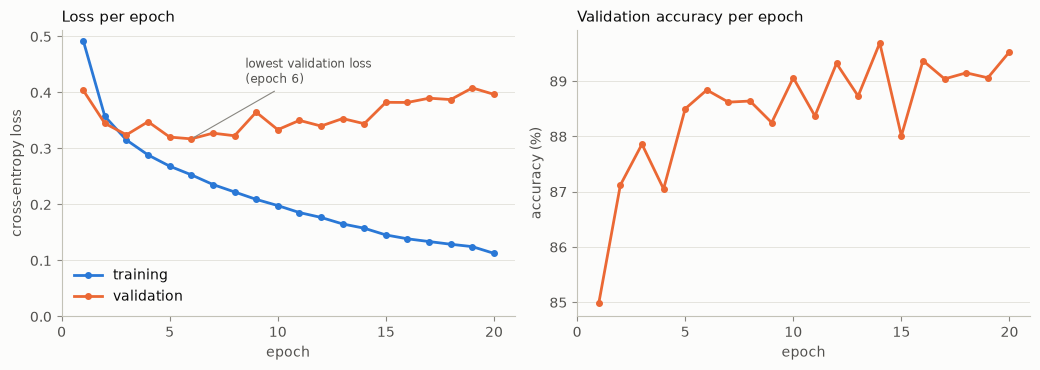

In [15]:
best_epoch = int(fc_history.val_loss.idxmin())
best = fc_history.loc[best_epoch]
last = fc_history.iloc[-1]
print(f"lowest validation loss: epoch {best_epoch}, loss {best.val_loss:.4f}, accuracy {best.val_accuracy:.2%}")
print(f"last epoch ({EPOCHS}):         loss {last.val_loss:.4f}, accuracy {last.val_accuracy:.2%}")
print(f"training loss fell from {fc_history.train_loss.iloc[0]:.4f} to {last.train_loss:.4f}")

TRAIN_COLOUR, VAL_COLOUR = SERIES[0], SERIES[1]  # training = blue, validation = orange, in every plot
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(10.5, 3.8))
ax_loss.plot(fc_history.index, fc_history.train_loss, color=TRAIN_COLOUR, lw=2, marker="o", ms=4,
             label="training")
ax_loss.plot(fc_history.index, fc_history.val_loss, color=VAL_COLOUR, lw=2, marker="o", ms=4,
             label="validation")
ax_loss.annotate(f"lowest validation loss\n(epoch {best_epoch})", xy=(best_epoch, best.val_loss),
                 xytext=(best_epoch + 2.5, best.val_loss + 0.1), fontsize=8.5, color=INK_SECONDARY,
                 arrowprops={"arrowstyle": "-", "color": INK_MUTED, "lw": 0.8})
ax_loss.set_xlabel("epoch")
ax_loss.set_ylabel("cross-entropy loss")
ax_loss.set_title("Loss per epoch", loc="left")
ax_loss.set_ylim(0, None)
ax_loss.grid(axis="y")
ax_loss.set_axisbelow(True)
ax_loss.legend(loc="lower left")

ax_acc.plot(fc_history.index, 100 * fc_history.val_accuracy, color=VAL_COLOUR, lw=2, marker="o", ms=4)
ax_acc.set_xlabel("epoch")
ax_acc.set_ylabel("accuracy (%)")
ax_acc.set_title("Validation accuracy per epoch", loc="left")
ax_acc.grid(axis="y")
ax_acc.set_axisbelow(True)
for ax in (ax_loss, ax_acc):
    ax.set_xticks(range(0, EPOCHS + 1, 5))
fig.tight_layout()
plt.show()

**What the curves show.** The training loss falls in every epoch, but the validation loss is
lowest after about 6 epochs and then rises again. From there on the model is learning details of
its 50,000 training images that do not help on new images: it has started to **overfit**.

Validation accuracy hardly suffers (it stays between 88% and 90%), so what goes wrong? The model
becomes *more confident*, also in its wrong answers, and cross-entropy punishes confident
mistakes hard (2c). The mistakes in 2f show this. Section 3 makes overfitting much stronger on
purpose and shows three ways to stop it.

The small ups and downs from one epoch to the next are noise: every epoch sees the mini-batches
in a different order. Do not read meaning into a single epoch.

### 2f. Looking at the mistakes

Accuracy is one number. A **confusion matrix** shows *which* classes get mixed up: each row is
the true class, each column the class the model predicted, so the diagonal holds the correct
answers. Below, the diagonal is grey and only the mistakes are coloured, darker for more.

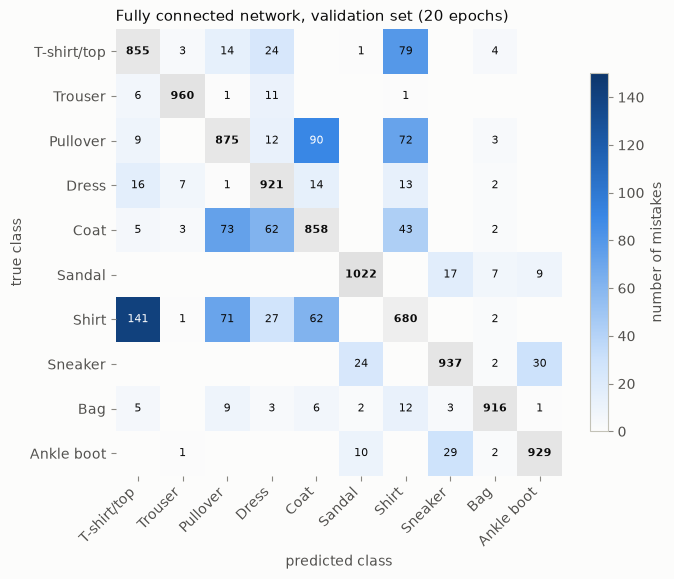

accuracy per class, worst first:
Shirt          69.1
Coat           82.0
Pullover       82.5
T-shirt/top    87.2
Sneaker        94.4
Dress          94.6
Ankle boot     95.7
Bag            95.7
Sandal         96.9
Trouser        98.1


In [16]:
val_logits, val_labels = predict(fc_model, val_loader)
val_predictions = val_logits.argmax(dim=1)


def confusion_matrix(labels: torch.Tensor, predictions: torch.Tensor) -> np.ndarray:
    """10 x 10 counts: row = true class, column = predicted class."""
    return torch.bincount(labels * 10 + predictions, minlength=100).reshape(10, 10).numpy()


MISTAKE_CMAP = LinearSegmentedColormap.from_list(
    "mistakes", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])


def plot_confusion(cm: np.ndarray, title: str) -> None:
    """Mistakes coloured by count (same blue scale for every model); correct answers in grey."""
    mistakes = np.ma.masked_where(np.eye(10, dtype=bool), cm)
    fig, ax = plt.subplots(figsize=(7.2, 6.2))
    image = ax.imshow(mistakes, cmap=MISTAKE_CMAP, vmin=0, vmax=max(150, mistakes.max()))
    ax.imshow(np.ma.masked_where(~np.eye(10, dtype=bool), cm), cmap="Greys", vmin=0, vmax=5000)
    for i in range(10):
        for j in range(10):
            if cm[i, j] == 0:
                continue
            dark = i != j and cm[i, j] > 0.55 * max(150, mistakes.max())
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="#ffffff" if dark else INK, fontweight="bold" if i == j else None)
    ax.set_xticks(range(10), CLASSES, rotation=45, ha="right")
    ax.set_yticks(range(10), CLASSES)
    ax.set_xlabel("predicted class")
    ax.set_ylabel("true class")
    ax.set_title(title, loc="left")
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.colorbar(image, ax=ax, shrink=0.75, label="number of mistakes")
    plt.show()


fc_confusion = confusion_matrix(val_labels, val_predictions)
pd.DataFrame(fc_confusion, index=CLASSES, columns=CLASSES).to_csv(RESULTS_DIR / "stage1_fc_confusion.csv")
plot_confusion(fc_confusion, f"Fully connected network, validation set ({EPOCHS} epochs)")

per_class = pd.Series(np.diag(fc_confusion) / fc_confusion.sum(axis=1), index=CLASSES, name="accuracy")
print("accuracy per class, worst first:")
print((100 * per_class.sort_values()).round(1).to_string())

The mistakes the model is *most sure about*: wrong answers with the highest predicted
probability. Looking at them tells you whether the model is stupid or the task is hard (or the
label is wrong).

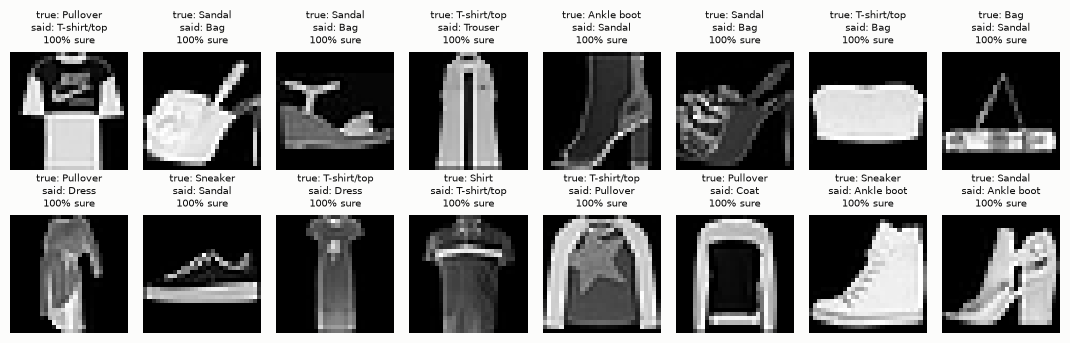

In [17]:
def show_confident_mistakes(logits: torch.Tensor, labels: torch.Tensor, n: int = 16) -> None:
    """Grid of the n wrong predictions with the highest probability for the wrong class."""
    probabilities = torch.softmax(logits, dim=1)
    confidence, predictions = probabilities.max(dim=1)
    wrong = torch.nonzero(predictions != labels).flatten()
    worst = wrong[confidence[wrong].argsort(descending=True)[:n]]
    fig, axes = plt.subplots(2, n // 2, figsize=(n // 2 * 1.35, 3.6))
    for ax, i in zip(axes.flat, worst.tolist()):
        ax.imshow(train_full.data[val_idx[i]], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"true: {CLASSES[labels[i]]}\nsaid: {CLASSES[predictions[i]]}\n"
                     f"{confidence[i]:.0%} sure", fontsize=7.5)
        ax.axis("off")
    fig.tight_layout()
    plt.show()


show_confident_mistakes(val_logits, val_labels)

**What the mistakes show.**

- **Mix-ups happen between classes with the same shape.** Most mistakes are among the tops
  (shirt, T-shirt/top, pullover, coat) and among the shoes (sneaker, sandal, ankle boot).
  Shirt is by far the hardest class: only 69% of shirts are recognised, and 141 of them are
  called T-shirt/top. Trousers and bags are almost never confused with anything.
- **The model is sure of itself even when it is wrong.** Its most confident mistakes get about
  100% probability. This is the overconfidence that makes the validation loss rise in 2e.
- **Some labels are doubtful.** A few of these images look more like the predicted class than
  their label (the first one, labelled Pullover, looks like a T-shirt). No model can get those
  right, so 100% accuracy is not a realistic goal.

For MVTec AD we will use the same habit: look at the most confident mistakes to tell whether a
missed defect is the model's fault or a defect that is barely visible.

## 3. Overfitting on purpose, and three ways to stop it

**Overfitting** means the model learns its training images so well, noise and accidents
included, that it does worse on new images. Think of a student who memorises last year's exam
answers: 100% on that exam, much less on a new one. Section 2 showed the first signs. Overfitting
gets much worse with little training data, because there are fewer examples to show which details
matter. This matters for MVTec AD, where a category has only 60 to 391 good training images.

To make it obvious, we train the same network on only **1,000 training images** (100 per class)
for 100 epochs, and still measure on all 10,000 validation images.

In [18]:
SMALL_PER_CLASS = 100
generator = torch.Generator().manual_seed(SEED)
small_idx = torch.cat([
    torch.nonzero(y_train == c).flatten()[
        torch.randperm(int((y_train == c).sum()), generator=generator)[:SMALL_PER_CLASS]]
    for c in range(10)
])
X_small, y_small = X_train[small_idx], y_train[small_idx]
print(f"small training set: {len(X_small):,} images, per class {torch.bincount(y_small).tolist()}")
print(f"validation set (unchanged): {len(X_val):,} images")

small training set: 1,000 images, per class [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
validation set (unchanged): 10,000 images


### 3a. Watching a model overfit

We now also measure accuracy on the **training** images, the same way as on the validation
images: after each epoch, in eval mode. The gap between the two is the clearest sign of
overfitting.

The training function below also has the options for early stopping (3b) and weight decay (3d);
they are explained there. It uses **AdamW**, which is Adam with weight decay built in. With
weight decay 0 it is the same as the Adam of section 2.

In [19]:
def train_model(model: nn.Module, x: torch.Tensor, y: torch.Tensor, max_epochs: int,
                weight_decay: float = 0.0, patience: int | None = None, seed: int = SEED,
                lr: float = 1e-3, augment: Callable[[torch.Tensor], torch.Tensor] | None = None,
                ) -> tuple[pd.DataFrame, int]:
    """Train with AdamW; after every epoch measure loss and accuracy on training AND validation data.

    weight_decay: shrink every weight a little at each step (3d). 0 = plain Adam, as in section 2.
    patience: early stopping (3b). Stop when the validation loss has not improved for this many
        epochs, then put back the weights of the best epoch. None = always train max_epochs.
    augment: random changes to the training images (section 5). Only the training batches are
        changed; the accuracy and loss are always measured on the unchanged images.
    Returns the history (one row per epoch) and the epoch whose weights the model ends with.
    """
    model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    train_loader = make_loader(x, y, shuffle=True, seed=seed)
    train_eval_loader = make_loader(x, y, shuffle=False)  # same images, fixed order, for measuring
    best_loss, best_epoch, best_weights = float("inf"), 0, None
    rows = []
    for epoch in range(1, max_epochs + 1):
        start = time.perf_counter()
        train_one_epoch(model, train_loader, optimizer, augment)
        train_loss, train_accuracy = evaluate(model, train_eval_loader)
        val_loss, val_accuracy = evaluate(model, val_loader)
        rows.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                     "train_accuracy": train_accuracy, "val_accuracy": val_accuracy,
                     "seconds": time.perf_counter() - start})
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch
            best_weights = {k: v.detach().clone() for k, v in model.state_dict().items()}
        elif patience is not None and epoch - best_epoch >= patience:
            break  # no improvement for `patience` epochs: stop
    history = pd.DataFrame(rows).set_index("epoch")
    if patience is None:
        return history, epoch
    model.load_state_dict(best_weights)  # early stopping: go back to the best epoch
    return history, best_epoch


def weight_size(model: nn.Module) -> float:
    """Square root of the sum of all squared weights (biases left out): one number for 'how big'."""
    return torch.sqrt(sum((p.detach() ** 2).sum() for n, p in model.named_parameters()
                          if n.endswith("weight"))).item()


small_data_results: list[dict] = []  # one summary row per training run on the 1,000 images


def run(setting: str, make_model, x: torch.Tensor, y: torch.Tensor, max_epochs: int,
        weight_decay: float = 0.0, patience: int | None = None, seed: int = SEED,
        augment: Callable[[torch.Tensor], torch.Tensor] | None = None,
        ) -> tuple[pd.DataFrame, nn.Module, dict]:
    """Train one new model with a fixed seed. Returns its history, the model and a summary row."""
    set_seed(seed)
    model = make_model()
    start = time.perf_counter()
    history, used_epoch = train_model(model, x, y, max_epochs, weight_decay, patience, seed,
                                      augment=augment)
    used = history.loc[used_epoch]
    summary = {"setting": setting, "seed": seed, "training_images": len(x),
               "epochs_trained": len(history), "epoch_used": used_epoch,
               "train_accuracy": used.train_accuracy, "val_accuracy": used.val_accuracy,
               "val_loss": used.val_loss, "lowest_val_loss": history.val_loss.min(),
               "weight_size": weight_size(model), "seconds": time.perf_counter() - start}
    return history, model, summary


def plot_history(history: pd.DataFrame, title: str, used_epoch: int | None = None,
                 max_epoch: int | None = None) -> None:
    """Training vs validation: loss (log scale) and accuracy per epoch."""
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(10.5, 3.8))
    for ax, metric, scale in ((ax_loss, "loss", 1), (ax_acc, "accuracy", 100)):
        ax.plot(history.index, scale * history[f"train_{metric}"], color=TRAIN_COLOUR, lw=2,
                label="training")
        ax.plot(history.index, scale * history[f"val_{metric}"], color=VAL_COLOUR, lw=2,
                label="validation")
        if used_epoch is not None:
            ax.axvline(used_epoch, color=INK_MUTED, lw=1, ls=":",
                       label=f"weights kept (epoch {used_epoch})")
        ax.set_xlabel("epoch")
        ax.set_xlim(0, max_epoch or history.index.max())
        ax.grid(axis="y")
        ax.set_axisbelow(True)
    losses = history[["train_loss", "val_loss"]]
    if losses.max().max() / losses.min().min() > 10:  # log scale only for a wide range
        ax_loss.set_yscale("log")
        ax_loss.set_ylabel("cross-entropy loss (log scale)")
    else:
        ax_loss.set_ylabel("cross-entropy loss")
    ax_loss.set_title("Loss per epoch", loc="left")
    ax_loss.legend(loc="best")
    ax_acc.set_ylabel("accuracy (%)")
    ax_acc.set_title("Accuracy per epoch", loc="left")
    fig.suptitle(title, x=0.01, ha="left")
    fig.tight_layout()
    plt.show()

training time: 5.7 s for 100 epochs
after 100 epochs:  training   accuracy 100.00%, loss 0.0005
                   validation accuracy 81.23%, loss 1.0787
lowest validation loss: 0.5509 at epoch 13 (accuracy 80.87%)


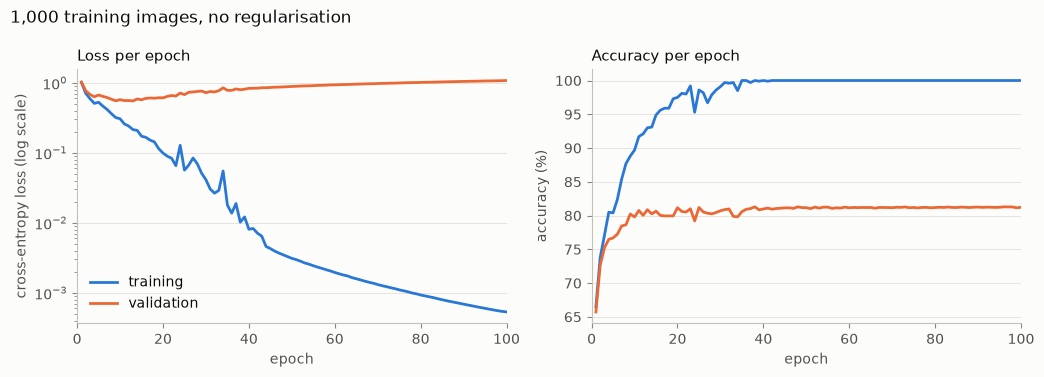

In [20]:
SMALL_EPOCHS = 100
plain_history, plain_model, plain_summary = run("no regularisation", FullyConnected,
                                                X_small, y_small, SMALL_EPOCHS)
small_data_results.append(plain_summary)

last = plain_history.iloc[-1]
lowest_epoch = int(plain_history.val_loss.idxmin())
print(f"training time: {plain_summary['seconds']:.1f} s for {SMALL_EPOCHS} epochs")
print(f"after {SMALL_EPOCHS} epochs:  training   accuracy {last.train_accuracy:.2%}, loss {last.train_loss:.4f}")
print(f"                   validation accuracy {last.val_accuracy:.2%}, loss {last.val_loss:.4f}")
print(f"lowest validation loss: {plain_history.val_loss.min():.4f} at epoch {lowest_epoch} "
      f"(accuracy {plain_history.loc[lowest_epoch].val_accuracy:.2%})")
plot_history(plain_history, "1,000 training images, no regularisation")

**What happened.** After about 40 epochs the network gets every training image right (100%),
and by epoch 100 its training loss is 0.0005: it has memorised the 1,000 images. On the
validation images it reaches about 81% and stays there. The validation loss is lowest at epoch
13 (0.55) and then doubles to 1.08: the model becomes more and more certain about answers that
are wrong for new images. The gap between the blue and the orange lines *is* the overfitting:
100% against 81%. For comparison, the same network trained on all 50,000 images reached about
89% in section 2.

### 3b. Early stopping

The simplest fix: stop when the model stops getting better on the validation set, and keep the
weights from its best epoch. After every epoch we compare the validation loss with the best so
far. If it has not improved for **patience** epochs (here 10), we stop and put back the best
weights. The patience lets the model ride out the noisy ups and downs we saw in 2e. Because the
validation set now chooses the epoch, its numbers become slightly optimistic; that is one more
reason the test set stays untouched until the end.

stopped after epoch 23, kept the weights of epoch 13
training time: 1.3 s (without early stopping: 5.7 s)
validation accuracy 80.87%, loss 0.5509


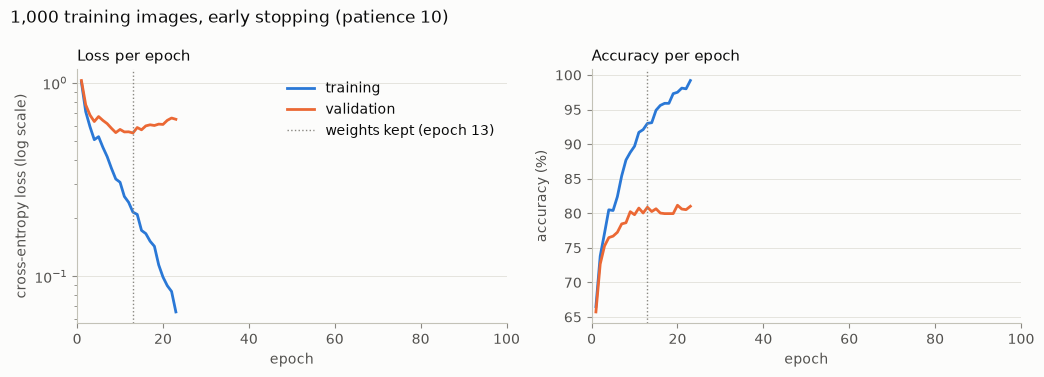

In [21]:
PATIENCE_SMALL = 10
es_history, es_model, es_summary = run("early stopping", FullyConnected, X_small, y_small,
                                       SMALL_EPOCHS, patience=PATIENCE_SMALL)
small_data_results.append(es_summary)

print(f"stopped after epoch {es_summary['epochs_trained']}, kept the weights of epoch {es_summary['epoch_used']}")
print(f"training time: {es_summary['seconds']:.1f} s (without early stopping: {plain_summary['seconds']:.1f} s)")
print(f"validation accuracy {es_summary['val_accuracy']:.2%}, loss {es_summary['val_loss']:.4f}")
plot_history(es_history, "1,000 training images, early stopping (patience 10)",
             used_epoch=es_summary["epoch_used"], max_epoch=SMALL_EPOCHS)

**What happened.** Up to epoch 23 the curves are the same as in 3a, because the seed is the
same. The validation loss was lowest at epoch 13; after 10 more epochs without improvement,
training stopped and the weights of epoch 13 were put back. The model keeps the lowest
validation loss (0.55 instead of 1.08), and training took about a quarter of the time.

Its accuracy (80.87%) is a little *lower* than after 100 epochs (81.23%): the epoch with the
lowest loss is not the epoch with the highest accuracy. Whether a 0.4-point difference is real
or chance, we check in 3e.

### 3c. Dropout

**Dropout** switches off a random part of the hidden units at every training step. With
p = 0.5, each unit's output is set to 0 with probability 50%, and the others are doubled so the
total stays about the same. The network can never count on one particular unit, so it has to
spread what it knows over many units, which makes memorising single images harder. Dropout only
acts during training: `model.eval()` turns it off, so predictions are not random. Its strength p
must be chosen. Too little and the model still overfits; too much and it cannot even learn the
training images, which is called **underfitting**.

training mode: tensor([0., 0., 0., 0., 0., 2., 0., 2., 2., 2.])
eval mode:     tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


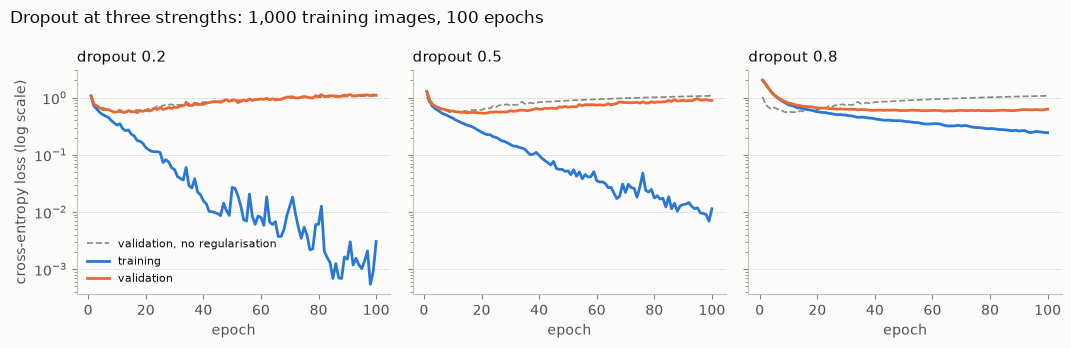

,train_accuracy,val_accuracy,val_loss,lowest_val_loss,weight_size
setting,,,,,
no regularisation,1.000,0.8123,1.0787,0.5509,18.3483
dropout 0.2,0.999,0.8070,1.0976,0.5483,19.8687
dropout 0.5,0.997,0.8113,0.8908,0.5319,21.0193
dropout 0.8,0.917,0.8105,0.6284,0.5819,19.1624


In [22]:
dropout = nn.Dropout(p=0.5)
values = torch.ones(10)
dropout.train()
print("training mode:", dropout(values))
dropout.eval()
print("eval mode:    ", dropout(values))


class FullyConnectedDropout(nn.Module):
    """The section 2 network with dropout after each hidden layer. Dropout adds no weights."""

    def __init__(self, dropout: float, hidden: int = 256) -> None:
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, 10),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(x)


def plot_sweep(histories: dict[str, pd.DataFrame], title: str) -> None:
    """One loss panel per setting, same scales. Dashed grey: validation loss without regularisation."""
    fig, axes = plt.subplots(1, len(histories), figsize=(3.6 * len(histories), 3.5), sharey=True)
    for ax, (name, history) in zip(axes, histories.items()):
        ax.plot(plain_history.index, plain_history.val_loss, color=INK_MUTED, lw=1.2, ls="--",
                label="validation, no regularisation")
        ax.plot(history.index, history.train_loss, color=TRAIN_COLOUR, lw=2, label="training")
        ax.plot(history.index, history.val_loss, color=VAL_COLOUR, lw=2, label="validation")
        ax.set_yscale("log")
        ax.set_title(name, loc="left")
        ax.set_xlabel("epoch")
        ax.grid(axis="y")
        ax.set_axisbelow(True)
    axes[0].set_ylabel("cross-entropy loss (log scale)")
    axes[0].legend(loc="lower left", fontsize=8)
    fig.suptitle(title, x=0.01, ha="left")
    fig.tight_layout()
    plt.show()


SWEEP_COLUMNS = ["train_accuracy", "val_accuracy", "val_loss", "lowest_val_loss", "weight_size"]


def sweep_table(settings: list[str]) -> pd.DataFrame:
    """Summary rows (seed SEED) for the given settings, values at the last epoch."""
    rows = pd.DataFrame(small_data_results)
    rows = rows[(rows.seed == SEED) & rows.setting.isin(settings)].set_index("setting")
    return rows.loc[settings, SWEEP_COLUMNS].round(4)


dropout_histories = {}
for p in (0.2, 0.5, 0.8):
    history, _, summary = run(f"dropout {p}", lambda: FullyConnectedDropout(p), X_small, y_small,
                              SMALL_EPOCHS)
    dropout_histories[f"dropout {p}"] = history
    small_data_results.append(summary)

plot_sweep(dropout_histories, f"Dropout at three strengths: 1,000 training images, {SMALL_EPOCHS} epochs")
sweep_table(["no regularisation", *dropout_histories])

**What happened.**

- **Dropout 0.2** changes almost nothing: the training loss still falls to about 0.001, and the
  validation loss ends as high as without regularisation.
- **Dropout 0.5** slows the memorising. The validation loss rises less (0.89 after 100 epochs
  instead of 1.08), and its lowest validation loss is the best of this sweep (0.53).
- **Dropout 0.8** is so strong that the network can no longer learn all its training images
  (91.7% training accuracy): it starts to **underfit**. Its validation loss stays low and flat,
  but its lowest validation loss (0.58) is worse than without dropout.
- **Validation accuracy stays at about 81%** in all four settings.
- Dropout does **not** make the weights smaller (`weight_size` even grows a little). It works by
  forcing the network to spread what it knows, not by shrinking weights. Weight decay, next,
  works the other way.

### 3d. Weight decay

An overfitting network often has some very large weights: it builds sharp rules that fit single
training images exactly. **Weight decay** shrinks every weight by a small fraction at every
step. With AdamW the fraction is learning rate × weight decay, so weight decay 1.0 shrinks each
weight by 0.001 × 1.0 = 0.1% per step. A weight stays large only if the gradient keeps pushing
it there, so only patterns that help on many training images survive. Like dropout, its
strength must be chosen; we try 0.1, 1 and 10. The column `weight_size` (the square root of the
sum of all squared weights) shows the shrinking.

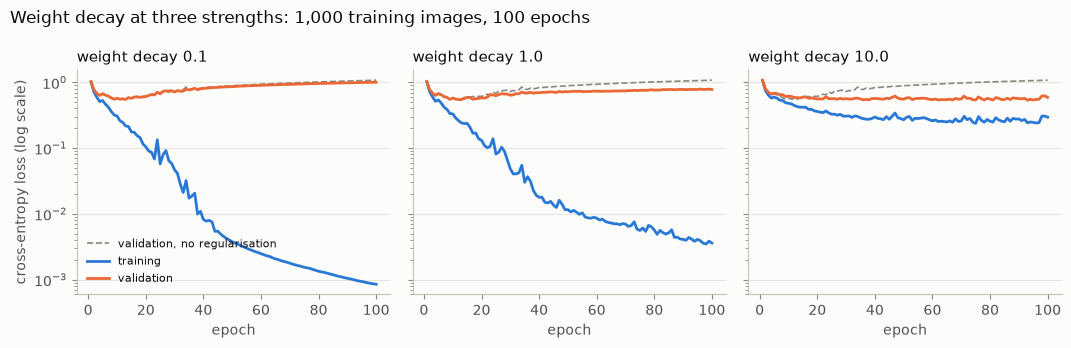

,train_accuracy,val_accuracy,val_loss,lowest_val_loss,weight_size
setting,,,,,
no regularisation,1.00,0.8123,1.0787,0.5509,18.3483
weight decay 0.1,1.00,0.8115,1.0030,0.5487,17.4050
weight decay 1.0,1.00,0.8154,0.7780,0.5461,12.4838
weight decay 10.0,0.92,0.7883,0.5902,0.5351,7.2181


In [23]:
decay_histories = {}
for weight_decay in (0.1, 1.0, 10.0):
    history, _, summary = run(f"weight decay {weight_decay}", FullyConnected, X_small, y_small,
                              SMALL_EPOCHS, weight_decay=weight_decay)
    decay_histories[f"weight decay {weight_decay}"] = history
    small_data_results.append(summary)

plot_sweep(decay_histories, f"Weight decay at three strengths: 1,000 training images, {SMALL_EPOCHS} epochs")
sweep_table(["no regularisation", *decay_histories])

**What happened.**

- **`weight_size` shows the shrinking:** 18.3 without weight decay, 17.4 with 0.1, 12.5 with
  1.0, 7.2 with 10.
- **Weight decay 0.1** is too weak to matter here. **Weight decay 1.0** keeps the validation
  loss lower (0.78 after 100 epochs instead of 1.08), while training accuracy still reaches 100%.
- **Weight decay 10** holds the validation loss down the most (0.59) but underfits: training
  accuracy only reaches 92%, and validation accuracy drops to 78.8%, more than 2 points below
  the others. Too strong has a real cost, so the strength has to be chosen on the validation set.
- For 3e we take the middle value of each sweep, dropout 0.5 and weight decay 1.0: both clearly
  change the curves without underfitting.

### 3e. All three together, and is the difference real?

Now dropout 0.5, weight decay 1.0 and early stopping together. Before we trust any difference,
we check how much results move by chance: the seed decides the starting weights, the order of
the mini-batches and which units dropout switches off. We train each setting with three
different seeds. A difference smaller than the spread between seeds is not a real difference.
We will use the same habit when we compare anomaly detection methods on MVTec AD.

In [24]:
SEEDS = (SEED, 1, 2)
settings = {
    "no regularisation": {"make_model": FullyConnected},
    "early stopping": {"make_model": FullyConnected, "patience": PATIENCE_SMALL},
    "dropout 0.5 + weight decay 1.0 + early stopping": {
        "make_model": lambda: FullyConnectedDropout(0.5), "weight_decay": 1.0,
        "patience": PATIENCE_SMALL},
}
done = {(r["setting"], r["seed"]) for r in small_data_results}
start = time.perf_counter()
for setting, options in settings.items():
    for seed in SEEDS:
        if (setting, seed) not in done:  # seed 42 of the first two already ran in 3a and 3b
            _, _, summary = run(setting, options["make_model"], X_small, y_small, SMALL_EPOCHS,
                                options.get("weight_decay", 0.0), options.get("patience"), seed)
            small_data_results.append(summary)
print(f"seed runs: {time.perf_counter() - start:.0f} s")

results_small = pd.DataFrame(small_data_results)
results_small.to_csv(RESULTS_DIR / "stage1_regularisation.csv", index=False)

by_seed = results_small[results_small.setting.isin(settings)]
seed_table = by_seed.groupby("setting", sort=False).agg(
    val_accuracy_mean=("val_accuracy", "mean"), val_accuracy_min=("val_accuracy", "min"),
    val_accuracy_max=("val_accuracy", "max"), val_loss_mean=("val_loss", "mean"),
    val_loss_min=("val_loss", "min"), val_loss_max=("val_loss", "max"),
    epochs_trained_mean=("epochs_trained", "mean"))
seed_table.round(4)

seed runs: 18 s


,val_accuracy_mean,val_accuracy_min,val_accuracy_max,val_loss_mean,val_loss_min,val_loss_max,epochs_trained_mean
setting,,,,,,,
no regularisation,0.8129,0.8123,0.8136,1.0705,1.0274,1.1053,100.0000
early stopping,0.8049,0.8020,0.8087,0.5484,0.5468,0.5509,21.3333
dropout 0.5 + weight decay 1.0 + early stopping,0.8104,0.8079,0.8144,0.5269,0.5250,0.5301,29.0000


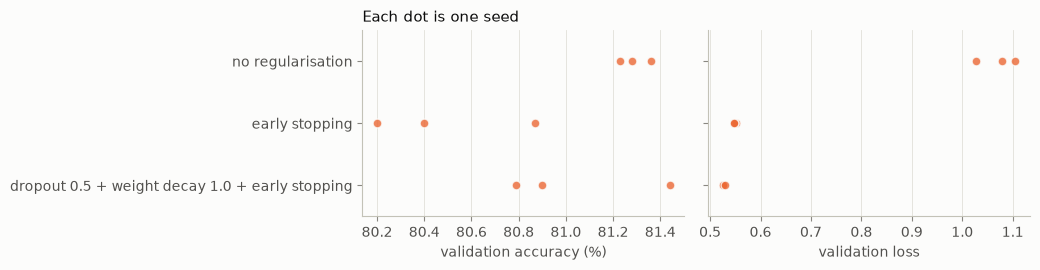

In [25]:
fig, (ax_acc, ax_loss) = plt.subplots(1, 2, figsize=(10.5, 2.8), sharey=True)
names = list(settings)
for y_pos, setting in enumerate(names):
    rows = by_seed[by_seed.setting == setting]
    for ax, column, scale in ((ax_acc, "val_accuracy", 100), (ax_loss, "val_loss", 1)):
        ax.scatter(scale * rows[column], [y_pos] * len(rows), s=40, color=VAL_COLOUR, alpha=0.8,
                   edgecolors="#fcfcfb", linewidths=1, zorder=3)
for ax in (ax_acc, ax_loss):
    ax.grid(axis="x")
    ax.set_axisbelow(True)
ax_acc.set_yticks(range(len(names)), names)
ax_acc.set_ylim(len(names) - 0.5, -0.5)
ax_acc.set_xlabel("validation accuracy (%)")
ax_loss.set_xlabel("validation loss")
ax_acc.set_title("Each dot is one seed", loc="left")
fig.tight_layout()
plt.show()

**What the seeds show.**

- **Validation loss:** about 1.07 without regularisation. **Early stopping alone halves it**
  (about 0.55), and adding dropout and weight decay brings it a little lower (about 0.53). These
  differences are much larger than the spread between seeds, so they are real.
- **Accuracy hardly changes:** all runs land between 80.2% and 81.4%. Early stopping alone is
  slightly lower (80.2–80.9%) than 100 epochs without it (81.2–81.4%), because it keeps the
  epoch with the lowest loss, not the highest accuracy. Adding dropout and weight decay wins back
  most of that (80.8–81.4%).
- **So here the three fixes cure overconfidence, not accuracy.** Trained on 1,000 images, the
  network is wrong on about 19% of new images whatever we do; what changes is how sure it is
  about those wrong answers. That still matters for this project: in Stage 4 we put thresholds
  on scores, and a model that is 100% sure about its mistakes leaves a threshold nothing to
  work with.
- **Early stopping does most of the work, and it saves time** (21 epochs on average instead of
  100). We use it in every training from now on.

### 3f. Back to all 50,000 training images

Do the fixes help when there is plenty of data? We train on the full training set with early
stopping (patience 5, at most 50 epochs). With 50 times more data the model needs less
regularisation, so besides the setting from 3e we also try a lighter one (dropout 0.3, weight
decay 0.1), and the **validation loss decides** which one we keep. That model is the fully
connected network we compare with the CNN in section 4.

In [26]:
full_settings = {
    "dropout 0.5 + weight decay 1.0 + early stopping": (0.5, 1.0),
    "dropout 0.3 + weight decay 0.1 + early stopping": (0.3, 0.1),
}
full_runs = {}
for setting, (p, weight_decay) in full_settings.items():
    history, model, summary = run(setting, lambda: FullyConnectedDropout(p), X_train, y_train,
                                  max_epochs=50, weight_decay=weight_decay, patience=5)
    full_runs[setting] = (history, model, summary)
    print(f"{setting}: stopped after epoch {summary['epochs_trained']}, kept epoch "
          f"{summary['epoch_used']}, {summary['seconds']:.0f} s")

section2_lowest = int(fc_history.val_loss.idxmin())
rows = [
    {"setting": "section 2: no regularisation, last epoch", "epoch_used": EPOCHS,
     "val_accuracy": fc_history.val_accuracy.iloc[-1], "val_loss": fc_history.val_loss.iloc[-1]},
    {"setting": "section 2: epoch with lowest validation loss", "epoch_used": section2_lowest,
     "val_accuracy": fc_history.val_accuracy[section2_lowest], "val_loss": fc_history.val_loss[section2_lowest]},
] + [{k: s[k] for k in ("setting", "epoch_used", "train_accuracy", "val_accuracy", "val_loss")}
     for _, _, s in full_runs.values()]
full_comparison = pd.DataFrame(rows).set_index("setting")
full_comparison.to_csv(RESULTS_DIR / "stage1_fc_full_data.csv")

# Keep the setting with the lowest validation loss for the comparison with the CNN.
fc_final_setting = min(full_runs, key=lambda s: full_runs[s][2]["val_loss"])
fc_final_history, fc_final, fc_final_summary = full_runs[fc_final_setting]
print(f"\nkept for section 4: {fc_final_setting}")
full_comparison.round(4)

dropout 0.5 + weight decay 1.0 + early stopping: stopped after epoch 22, kept epoch 17, 16 s


dropout 0.3 + weight decay 0.1 + early stopping: stopped after epoch 23, kept epoch 18, 17 s

kept for section 4: dropout 0.3 + weight decay 0.1 + early stopping


,epoch_used,val_accuracy,val_loss,train_accuracy
setting,,,,
"section 2: no regularisation, last epoch",20,0.8953,0.3967,NaN
section 2: epoch with lowest validation loss,6,0.8884,0.3172,NaN
dropout 0.5 + weight decay 1.0 + early stopping,17,0.8671,0.3620,0.8789
dropout 0.3 + weight decay 0.1 + early stopping,18,0.8924,0.2980,0.9243


**What happened on all 50,000 images.**

- **The setting from 3e is too strong here.** With dropout 0.5 and weight decay 1.0, training
  accuracy only reaches 87.9% and validation accuracy drops to 86.7%. The right strength depends
  on how much data there is: with 50 times more images, memorising is less of a danger.
- **The lighter setting** (dropout 0.3, weight decay 0.1) has the lowest validation loss of all
  (0.298, against 0.317 at the best epoch of section 2 and 0.397 after 20 epochs), with 89.2%
  accuracy. This is the model we keep.
- **Accuracy is again almost unchanged** (88.8–89.5% in section 2). This fully connected network
  seems to be stuck near 89% on Fashion-MNIST, however we regularise it. To do better, we need a
  model that understands images better, not one that memorises less: the CNN in section 4.

## 4. A small convolutional network (CNN)

The fully connected network sees an image as 784 separate numbers. It does not know which pixels
are neighbours: if we shuffled the pixels of every image in the same way, it would learn just as
well. But images have structure. An edge, a seam or a scratch is a small pattern of neighbouring
pixels, and the same pattern means the same thing wherever it appears. A **convolutional neural
network (CNN)** is built around exactly that. Every method we use on MVTec AD (the autoencoder,
the pretrained ResNets) is a CNN.

### 4a. Convolution: one small filter slid over the image

A **convolution** slides a small grid of weights, called a **filter** (or kernel), over the
image. At each position it multiplies the filter with the 3 × 3 pixels under it and adds the 9
products into one number. The result is a new image, a **feature map**, that is large wherever
the image looks like the filter. The filter below has −1 on the left and +1 on the right, so it
responds to a change from dark to bright, left to right: a vertical edge. In a CNN nobody designs
the filters; their weights are learned by backpropagation like any other weight. And the same 9
weights are used at every position, which is why a convolution layer needs so few weights.

The example: a 5 × 5 image, dark (0) in the two left columns and bright (1) in the three right
ones. At the top-left position the filter covers columns 0–2, and each row gives
(−1)·0 + 0·0 + 1·1 = 1, so the sum over three rows is **3**. Over columns 2–4 the image is
flat, and each row gives (−1)·1 + 0·1 + 1·1 = **0**.

In [27]:
tiny_image = torch.tensor([[0, 0, 1, 1, 1]] * 5, dtype=torch.float32)
vertical_edge = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)

# By hand at the top-left position: multiply the filter with the 3 x 3 pixels under it, add up.
patch = tiny_image[0:3, 0:3]
print("pixels under the filter at the top-left:\n", patch)
print("sum of filter x pixels =", (vertical_edge * patch).sum().item())

# PyTorch does every position at once. conv2d wants (batch, channels, height, width) for both.
feature_map = F.conv2d(tiny_image[None, None], vertical_edge[None, None])
print("\nfeature map from F.conv2d, one value per filter position:\n", feature_map[0, 0])

pixels under the filter at the top-left:
 tensor([[0., 0., 1.],
        [0., 0., 1.],
        [0., 0., 1.]])
sum of filter x pixels = 3.0

feature map from F.conv2d, one value per filter position:
 tensor([[3., 3., 0.],
        [3., 3., 0.],
        [3., 3., 0.]])


The same two hand-made filters on a real image: the vertical-edge filter above, and the same
filter turned on its side, which responds to horizontal edges. **Red** means dark-to-bright (left
to right, or top to bottom), **blue** the opposite, **grey** no change.

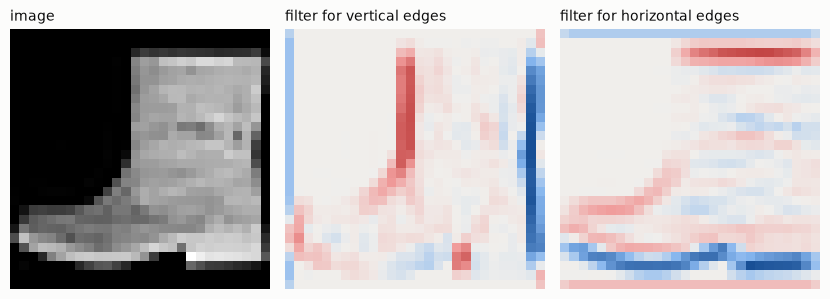

In [28]:
DIVERGING_CMAP = LinearSegmentedColormap.from_list(
    "diverging", ["#184f95", "#86b6ef", "#f0efec", "#f19c9b", "#b8302f"])  # blue - grey - red
ACTIVATION_CMAP = LinearSegmentedColormap.from_list(
    "activation", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])  # 0 = white

boot_position = int(torch.nonzero(y_val == CLASSES.index("Ankle boot"))[0])
boot = X_val[boot_position]  # scaled model input, shape (1, 28, 28)
hand_filters = {"vertical edges": vertical_edge, "horizontal edges": vertical_edge.T}

fig, axes = plt.subplots(1, 3, figsize=(8.4, 3))
axes[0].imshow(train_full.data[val_idx[boot_position]], cmap="gray", vmin=0, vmax=255)
axes[0].set_title("image", loc="left", fontsize=10)
for ax, (name, kernel) in zip(axes[1:], hand_filters.items()):
    edges = F.conv2d(boot[None], kernel[None, None], padding=1)[0, 0]  # padding keeps 28 x 28
    limit = edges.abs().max()
    ax.imshow(edges, cmap=DIVERGING_CMAP, vmin=-limit, vmax=limit)
    ax.set_title(f"filter for {name}", loc="left", fontsize=10)
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()

**What the filters show.** The vertical-edge filter lights up along the front and the back of the
boot (red where the image goes from dark to bright, blue where it goes from bright to dark), and
the horizontal-edge filter along the top opening and the sole. Each filter finds one kind of
pattern, wherever it is in the image.

Look at the thin lines along the image border: they are **not in the image**. `padding=1` adds
zeros around the image, but after scaling (2a) the black background is about −0.81, so the zero
border looks like a slightly brighter frame, and the filters see an "edge" there. Padding can
create fake responses at the border. Keep this in mind for MVTec AD, where some defects lie near
the edge of the image (Stage 0).

### 4b. Pooling: keeping the strongest response

**Max pooling** shrinks a feature map by keeping only the largest value in each 2 × 2 block, so
28 × 28 becomes 14 × 14. It keeps how strongly a filter responded and drops exactly where, to
within a pixel or two. That makes the network a little tolerant to small shifts and cuts the
work for the next layer by 4. After two rounds of convolution and pooling, each number depends
on a 10 × 10 region of the original image instead of 3 × 3. So the second layer's filters can
respond to larger shapes (a collar, a heel) built from the edges the first layer found.

In [29]:
blocks = torch.tensor([[1, 3, 2, 0],
                       [4, 2, 1, 1],
                       [0, 1, 5, 2],
                       [2, 0, 3, 4]], dtype=torch.float32)
print("4 x 4 input:\n", blocks)
print("max pooling 2 x 2 -> 2 x 2:\n", F.max_pool2d(blocks[None, None], kernel_size=2)[0, 0])

4 x 4 input:
 tensor([[1., 3., 2., 0.],
        [4., 2., 1., 1.],
        [0., 1., 5., 2.],
        [2., 0., 3., 4.]])
max pooling 2 x 2 -> 2 x 2:
 tensor([[4., 2.],
        [2., 5.]])


### 4c. The network

Two rounds of convolution, ReLU and max pooling, then one linear layer that turns what the
filters found into 10 class scores. The first convolution has 32 filters, so it makes 32 feature
maps, also called **channels**. Each of the 64 filters in the second convolution looks at all 32
maps at once, so it has 3 × 3 × 32 weights. `padding=1` adds a border of zeros around the input
so a 3 × 3 filter keeps the size the same (28 × 28 stays 28 × 28). We use the same
regularisation as the fully connected network we kept in 3f: dropout 0.3 (before the linear
layer), weight decay 0.1 and early stopping. That way the comparison is about the architecture,
not the training recipe.

Below, one mini-batch of 128 images goes through the layers one by one, so you can follow the
shapes.

In [30]:
class SmallCNN(nn.Module):
    """Conv -> ReLU -> pool, twice, then one linear layer to 10 class scores."""

    def __init__(self, dropout: float = 0.3) -> None:
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),   # 32 filters of 3x3 on the grayscale image
            nn.ReLU(),
            nn.MaxPool2d(2),                              # 28x28 -> 14x14
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # 64 filters, each 3x3 over all 32 maps
            nn.ReLU(),
            nn.MaxPool2d(2),                              # 14x14 -> 7x7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                                 # 64 maps x 7 x 7 = 3,136 numbers
            nn.Dropout(dropout),
            nn.Linear(64 * 7 * 7, 10),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.features(x))


set_seed(SEED)
cnn_preview = SmallCNN()
x = example_images  # one mini-batch from 2a
print(f"{'input':<10} {tuple(x.shape)}")
for layer in [*cnn_preview.features, *cnn_preview.classifier]:
    x = layer(x)
    print(f"{layer.__class__.__name__:<10} {tuple(x.shape)}")
parameter_table(cnn_preview)

input      (128, 1, 28, 28)
Conv2d     (128, 32, 28, 28)
ReLU       (128, 32, 28, 28)
MaxPool2d  (128, 32, 14, 14)
Conv2d     (128, 64, 14, 14)
ReLU       (128, 64, 14, 14)
MaxPool2d  (128, 64, 7, 7)
Flatten    (128, 3136)
Dropout    (128, 3136)
Linear     (128, 10)


,shape,count
parameter,,
features.0.weight,"(32, 1, 3, 3)",288
features.0.bias,"(32,)",32
features.3.weight,"(64, 32, 3, 3)",18432
features.3.bias,"(64,)",64
classifier.2.weight,"(10, 3136)",31360
classifier.2.bias,"(10,)",10
total,,50186


The first convolution has 32 × (3 × 3 × 1) + 32 = 320 weights, the second 64 × (3 × 3 × 32) + 64
= 18,496, the linear layer 3,136 × 10 + 10 = 31,370. In total **50,186**, about a fifth of the
fully connected network's 269,322, because each filter's 9 weights are reused at every position
of the image.

### 4d. Training the CNN and comparing it with the fully connected network

The same `run` function and the same validation set as in section 3. A convolution is more work
per image than a linear layer, so an epoch takes longer: this cell runs about one and a half
minutes.

stopped after epoch 33, kept the weights of epoch 28; training time 100 s on mps


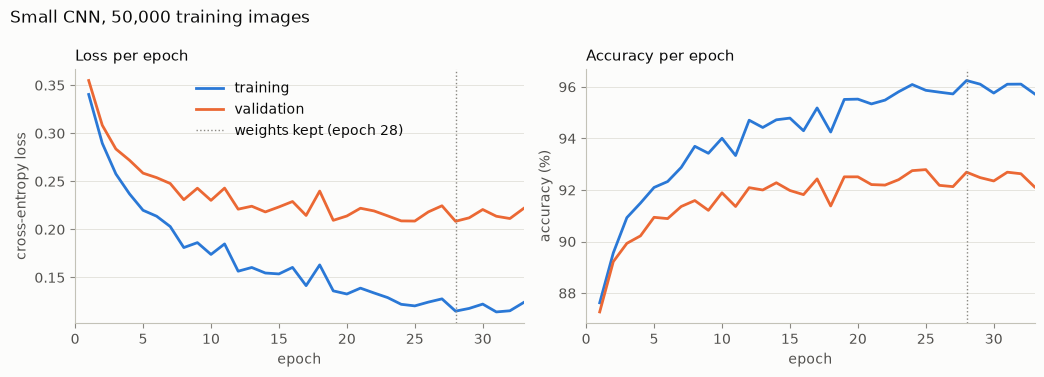

In [31]:
cnn_history, cnn_model, cnn_summary = run(
    "small CNN: dropout 0.3 + weight decay 0.1 + early stopping", SmallCNN, X_train, y_train,
    max_epochs=50, weight_decay=0.1, patience=5)
print(f"stopped after epoch {cnn_summary['epochs_trained']}, kept the weights of epoch "
      f"{cnn_summary['epoch_used']}; training time {cnn_summary['seconds']:.0f} s on {DEVICE}")
plot_history(cnn_history, "Small CNN, 50,000 training images", used_epoch=cnn_summary["epoch_used"])

In [32]:
def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters())


def comparison_row(name: str, model: nn.Module, summary: dict) -> dict:
    return {"model": name, "parameters": count_parameters(model),
            "epochs_trained": summary["epochs_trained"], "epoch_used": summary["epoch_used"],
            "train_accuracy": summary["train_accuracy"], "val_accuracy": summary["val_accuracy"],
            "val_loss": summary["val_loss"], "training_seconds": summary["seconds"],
            "seconds_per_epoch": summary["seconds"] / summary["epochs_trained"]}


fc_vs_cnn = pd.DataFrame([
    comparison_row("fully connected (3f)", fc_final, fc_final_summary),
    comparison_row("small CNN", cnn_model, cnn_summary),
]).set_index("model")
fc_vs_cnn.to_csv(RESULTS_DIR / "stage1_fc_vs_cnn.csv")
fc_vs_cnn.round(4)

,parameters,epochs_trained,epoch_used,train_accuracy,val_accuracy,val_loss,training_seconds,seconds_per_epoch
model,,,,,,,,
fully connected (3f),269322,23,18,0.9243,0.8924,0.2980,16.8317,0.7318
small CNN,50186,33,28,0.9625,0.9269,0.2084,100.0934,3.0331


Where does the CNN gain? Validation accuracy per class for both models, worst class (for the
fully connected network) at the top.

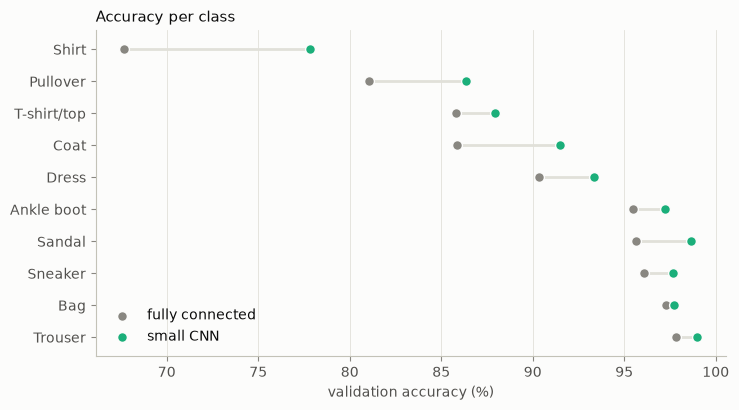

,fully connected,small CNN,difference
Shirt,67.7,77.8,10.2
Pullover,81.1,86.3,5.3
T-shirt/top,85.8,88.0,2.1
Coat,85.9,91.5,5.6
Dress,90.3,93.3,3.0
Ankle boot,95.5,97.2,1.8
Sandal,95.6,98.7,3.0
Sneaker,96.1,97.7,1.6
Bag,97.3,97.7,0.4
Trouser,97.9,99.0,1.1


In [33]:
def per_class_accuracy(model: nn.Module) -> pd.Series:
    logits, labels = predict(model, val_loader)
    cm = confusion_matrix(labels, logits.argmax(dim=1))
    return pd.Series(np.diag(cm) / cm.sum(axis=1), index=CLASSES)


per_class = pd.DataFrame({"fully connected": per_class_accuracy(fc_final),
                          "small CNN": per_class_accuracy(cnn_model)})
per_class["difference"] = per_class["small CNN"] - per_class["fully connected"]
per_class = per_class.sort_values("fully connected")
per_class.to_csv(RESULTS_DIR / "stage1_per_class_accuracy.csv")

FC_COLOUR, CNN_COLOUR = INK_MUTED, SERIES[2]  # fully connected = grey reference, CNN = green
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for y_pos, (name, row) in enumerate(per_class.iterrows()):
    ax.plot([100 * row["fully connected"], 100 * row["small CNN"]], [y_pos, y_pos], color=GRID,
            lw=2, zorder=1)
ax.scatter(100 * per_class["fully connected"], range(10), s=50, color=FC_COLOUR, zorder=2,
           edgecolors="#fcfcfb", linewidths=1, label="fully connected")
ax.scatter(100 * per_class["small CNN"], range(10), s=50, color=CNN_COLOUR, zorder=3,
           edgecolors="#fcfcfb", linewidths=1, label="small CNN")
ax.set_yticks(range(10), per_class.index)
ax.set_ylim(9.6, -0.6)
ax.set_xlabel("validation accuracy (%)")
ax.set_title("Accuracy per class", loc="left")
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()
(100 * per_class).round(1)

**What the comparison shows.**

- **The CNN is better with far fewer weights:** 92.7% validation accuracy against 89.2%
  (validation loss 0.208 against 0.298), with 50,186 weights instead of 269,322. Using the
  structure of images beats having more weights.
- **It is better in every class.** The biggest gains are where the fully connected network
  struggled most: shirt (+10.2 points), coat (+5.6) and pullover (+5.3). These classes differ
  mostly in small details such as collars, buttons or zips, which is probably where local
  filters help most.
- **Shirt is still the hardest class** (77.8%): the CNN narrows the gap but does not close it.
- **The price is compute.** One epoch takes about 4 times as long (about 3 s instead of 0.7 s), because every filter
  weight is used at every position of the image. With more epochs before early stopping (33
  instead of 23), training took about 100 s instead of about 17 s.

### 4e. What the CNN learned: filters and feature maps

The 32 filters of the first layer are 3 × 3 grids of weights, so we can simply draw them:
**red** for positive weights, **blue** for negative, each filter on its own scale. Nobody told
the network what to look for; whatever patterns appear here, backpropagation found them useful
for telling clothes apart.

The second layer's filters are harder to draw (3 × 3 × 32 numbers each). Instead we look at the
**feature maps**: what each filter responds to in one image, after ReLU (white = no response,
dark blue = strong response).

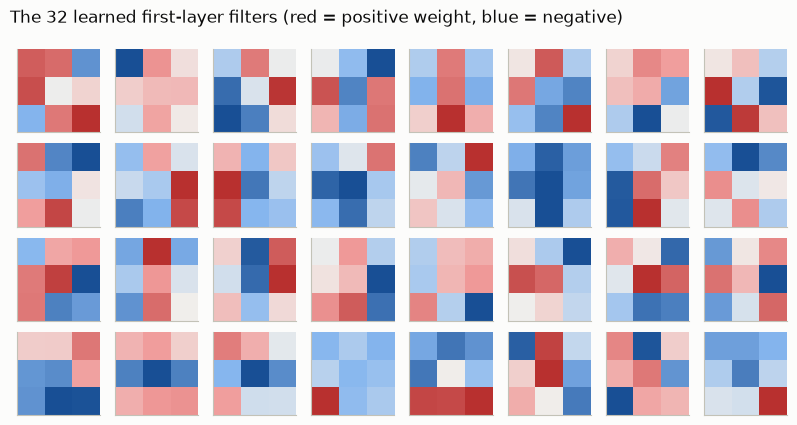

In [34]:
first_filters = cnn_model.features[0].weight.detach().cpu()[:, 0]  # (32, 3, 3)
fig, axes = plt.subplots(4, 8, figsize=(8, 4.3))
for ax, kernel in zip(axes.flat, first_filters):
    limit = kernel.abs().max()
    ax.imshow(kernel, cmap=DIVERGING_CMAP, vmin=-limit, vmax=limit)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("The 32 learned first-layer filters (red = positive weight, blue = negative)",
             x=0.01, ha="left")
fig.tight_layout()
plt.show()

layer 1 feature maps: (32, 28, 28) | layer 2 feature maps: (64, 14, 14)


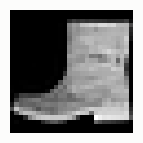

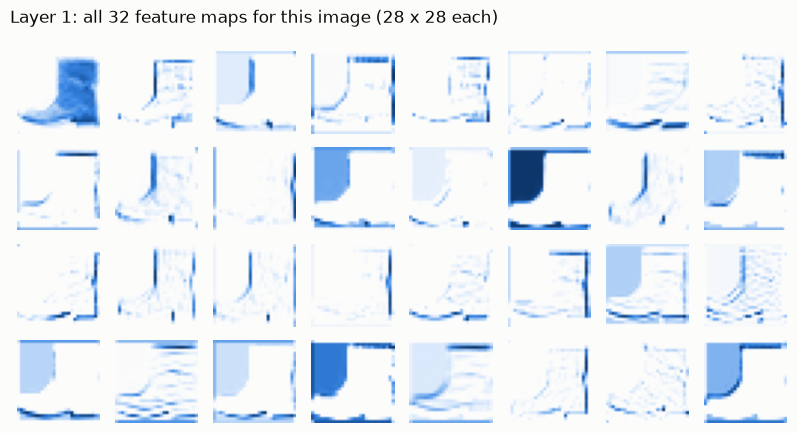

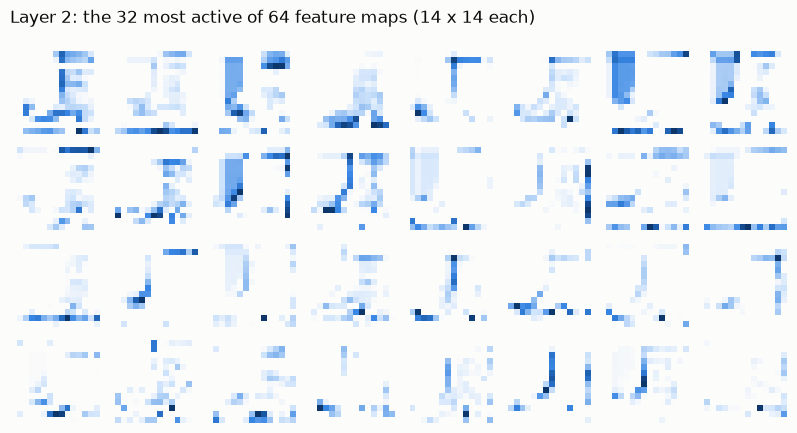

In [35]:
cnn_model.eval()
with torch.no_grad():
    image_input = boot[None].to(DEVICE)
    maps_layer1 = cnn_model.features[:2](image_input)[0].cpu()  # conv1 + ReLU: (32, 28, 28)
    maps_layer2 = cnn_model.features[:5](image_input)[0].cpu()  # conv2 + ReLU: (64, 14, 14)
print("layer 1 feature maps:", tuple(maps_layer1.shape), "| layer 2 feature maps:", tuple(maps_layer2.shape))


def show_maps(maps: torch.Tensor, title: str) -> None:
    """Feature maps in a 4 x 8 grid; each map on its own scale (white = 0)."""
    fig, axes = plt.subplots(4, 8, figsize=(8, 4.4))
    for ax, fmap in zip(axes.flat, maps):
        ax.imshow(fmap, cmap=ACTIVATION_CMAP, vmin=0, vmax=max(fmap.max().item(), 1e-6))
        ax.axis("off")
    fig.suptitle(title, x=0.01, ha="left")
    fig.tight_layout()
    plt.show()


fig, ax = plt.subplots(figsize=(1.6, 1.6))
ax.imshow(train_full.data[val_idx[boot_position]], cmap="gray", vmin=0, vmax=255)
ax.axis("off")
plt.show()
show_maps(maps_layer1, "Layer 1: all 32 feature maps for this image (28 x 28 each)")
strongest = maps_layer2.mean(dim=(1, 2)).argsort(descending=True)[:32]
show_maps(maps_layer2[strongest], "Layer 2: the 32 most active of 64 feature maps (14 x 14 each)")

**What the pictures show.**

- **The filters** are only 3 × 3, so they are hard to read one by one. Several have a light side
  and a dark side, like the hand-made edge filters in 4a but in other directions, diagonal ones
  too; others are mixtures. We designed none of them.
- **Layer 1 feature maps** look like outlines of the boot in different directions: some respond
  to its left edge, some to the sole, some to the top. A few respond to the black background,
  that is, to where the boot is *not*; that is information too.
- **Layer 2 feature maps** are coarser (14 × 14) and more selective: each responds to fewer,
  larger parts, such as the sole, the front edge, the top opening or a corner. Layer 2 combines
  the edges of layer 1 into parts.
- **This is the idea behind Stage 3.** A CNN trained on millions of photos (ImageNet) has learned
  filters for edges, textures and parts over many layers. Its feature maps describe what is where
  in an image, and PatchCore compares those descriptions between good images and a test image to
  find what is different.

## 5. Data augmentation

**Data augmentation** means changing every training image a little, at random, each time the
model sees it: mirror it, tilt it a few degrees, and so on. The label stays the same: a mirrored
bag is still a bag. Because the model sees a slightly different version of each image in every
epoch, it cannot memorise exact pixels, and it learns that these changes do not matter. That
makes augmentation a fourth fix for overfitting, next to the three in section 3, and it should
help most when there are few training images. Only the training images are augmented; validation
and test images are never changed, because they must look like the real images the model will
be used on.

The rule: **an augmentation is only allowed if the label stays the same and the new image could
really occur in the images the model will see.** In anomaly detection every training image has
the label "good", so an augmentation must never turn a good image into one that looks like a
defect. We check that on MVTec AD in 5c.

### 5a. Flips and rotations

A flip mirrors the image. A rotation turns it around its centre; this uncovers the four corners,
which must be filled with *something*. Here the background is black, which is about −0.81 after
scaling (2a), not 0. The functions below change each image in a batch differently, and they run
on the same device as the model, so augmenting costs almost no time.

In [36]:
# A black pixel after scaling (2a). Rotation must fill the corners it uncovers with this value.
BACKGROUND = (0.0 - PIXEL_MEAN) / PIXEL_STD


def flip(images: torch.Tensor, direction: str = "left-right") -> torch.Tensor:
    """Mirror every image: "left-right" mirrors the width, "upside-down" the height."""
    return images.flip(dims=[3] if direction == "left-right" else [2])  # (N, C, H, W)


def rotate(images: torch.Tensor, degrees: torch.Tensor, fill: float = BACKGROUND) -> torch.Tensor:
    """Rotate image i of the batch by degrees[i].

    affine_grid computes, for every output pixel, where it comes from in the input image;
    grid_sample reads the input there (mixing the 4 nearest pixels). Output pixels that come
    from outside the image (the corners) get the value 0, so we shift the images so that `fill`
    is 0 during the rotation, and shift them back after.
    """
    angles = torch.deg2rad(degrees.float())
    cos, sin, zero = torch.cos(angles), torch.sin(angles), torch.zeros_like(angles)
    rotation = torch.stack([torch.stack([cos, -sin, zero], dim=1),
                            torch.stack([sin, cos, zero], dim=1)], dim=1)  # (N, 2, 3)
    grid = F.affine_grid(rotation.to(images.device), list(images.shape), align_corners=False)
    return F.grid_sample(images - fill, grid, align_corners=False) + fill


def random_flip(images: torch.Tensor, direction: str = "left-right") -> torch.Tensor:
    """Mirror each image with probability 0.5: its own coin flip per image."""
    n = len(images)
    coin = (torch.rand(n) < 0.5).view(n, 1, 1, 1).to(images.device)
    return torch.where(coin, flip(images, direction), images)


def random_rotation(images: torch.Tensor, max_degrees: float,
                    fill: float = BACKGROUND) -> torch.Tensor:
    """Rotate each image by its own random angle between -max_degrees and +max_degrees."""
    degrees = (torch.rand(len(images)) * 2 - 1) * max_degrees
    return rotate(images, degrees, fill)


def flip_and_rotate(images: torch.Tensor) -> torch.Tensor:
    """A random left-right flip, then a random tilt of up to 10°. Both keep the label."""
    return random_rotation(random_flip(images), max_degrees=10)



The same three validation images, changed in different ways. Every image is drawn on the same
black-to-white scale, so a wrong fill colour shows up.

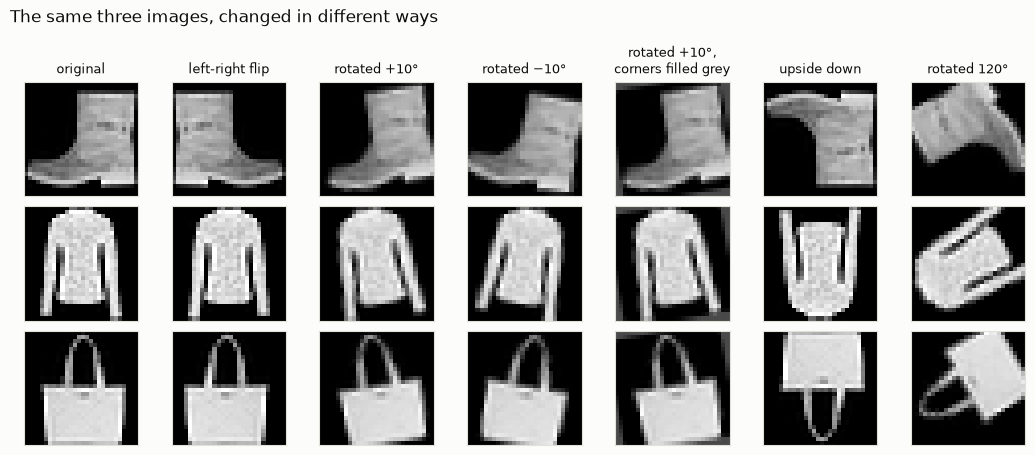

In [37]:
PIXEL_RANGE = dict(cmap="gray", vmin=BACKGROUND, vmax=(1.0 - PIXEL_MEAN) / PIXEL_STD)  # black..white

# One validation image of three classes, only for looking.
examples = torch.stack([X_val[torch.nonzero(y_val == CLASSES.index(name))[0, 0]]
                        for name in ("Ankle boot", "Shirt", "Bag")])
one = torch.ones(len(examples))
columns = {
    "original": examples,
    "left-right flip": flip(examples),
    "rotated +10°": rotate(examples, 10 * one),
    "rotated −10°": rotate(examples, -10 * one),
    "rotated +10°,\ncorners filled grey": rotate(examples, 10 * one, fill=0.0),
    "upside down": flip(examples, "upside-down"),
    "rotated 120°": rotate(examples, 120 * one),
}

fig, axes = plt.subplots(len(examples), len(columns), figsize=(10.5, 4.6))
for col, (title, images) in enumerate(columns.items()):
    for row in range(len(examples)):
        ax = axes[row, col]
        ax.imshow(images[row, 0], **PIXEL_RANGE)  # same black..white scale for every image
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():  # thin frame, so grey corners are visible against it
            spine.set_visible(True)
            spine.set_color(GRID)
    axes[0, col].set_title(title, fontsize=9)
fig.suptitle("The same three images, changed in different ways", x=0.01, ha="left")
fig.tight_layout()
plt.show()


**What the changes do.**

- **Left-right flip** keeps the label: a mirrored bag is still a bag. Tops and bags are nearly
  symmetric, so a mirrored one looks like any other photo. But in Fashion-MNIST almost every shoe
  points to the left (look at the shoes in 1d), so a mirrored shoe is an image the model will
  hardly ever be shown.
- **Rotation by ±10°** keeps the label too. The uncovered corners are filled with black, so they
  disappear into the background.
- **Corners filled grey:** filled with 0 instead of the background value, the corners show up as
  grey triangles, which no real photo has. It is the same trap as the padding in 4a: after
  scaling, 0 is not "nothing".
- **Upside down and 120°:** the label is still the same (an upside-down bag is still a bag), but
  no photo in Fashion-MNIST looks like this. With handwritten digits it would be worse: a 6
  upside down is a 9, so this augmentation would change the label.

During training, every image gets new random changes in every epoch. Here is the ankle boot as the
model might see it in 8 epochs, with a random left-right flip and a random rotation of up to
10° in either direction:

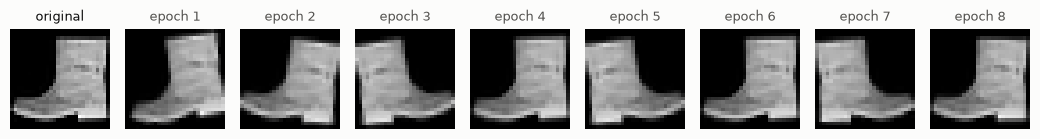

In [38]:
torch.manual_seed(SEED)
boot_copies = boot[None].repeat(8, 1, 1, 1)  # the ankle boot of 4a, 8 times: (8, 1, 28, 28)
draws = flip_and_rotate(boot_copies)  # 8 different random changes

fig, axes = plt.subplots(1, 9, figsize=(10.5, 1.6))
axes[0].imshow(boot[0], **PIXEL_RANGE)
axes[0].set_title("original", fontsize=9)
for epoch, (ax, image) in enumerate(zip(axes[1:], draws), start=1):
    ax.imshow(image[0], **PIXEL_RANGE)
    ax.set_title(f"epoch {epoch}", fontsize=9, color=INK_SECONDARY)
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()


### 5b. Does augmentation help?

The same small CNN as in section 4 (dropout 0.3, weight decay 0.1, early stopping), trained on
the 1,000 images of section 3, where overfitting is worst. Five settings, each with three seeds
(3e) so we can tell a real difference from chance:

- **no augmentation**: the baseline;
- **left-right flip**;
- **flip + rotation up to 10°**;
- **flip + rotation up to 10°, grey corners**: the same, with the wrong fill colour;
- **upside-down flip + rotation up to 180°**: images that never occur in Fashion-MNIST.

`train_one_epoch` (2d), `train_model` and `run` (3a) now take an `augment` argument; it was
`None` everywhere before, so sections 2-4 are unchanged. Augmented training learns more slowly,
so patience is 15 epochs instead of 10 and the limit 150 epochs instead of 100. 15 runs, about
3 minutes.

In [39]:
def flip_and_rotate_grey_corners(images: torch.Tensor) -> torch.Tensor:
    """As flip_and_rotate, but the uncovered corners get 0 (grey after scaling), not black."""
    return random_rotation(random_flip(images), max_degrees=10, fill=0.0)


def upside_down_any_angle(images: torch.Tensor) -> torch.Tensor:
    """Unrealistic: every Fashion-MNIST photo is upright, so these images never occur."""
    return random_rotation(random_flip(images, "upside-down"), max_degrees=180)


AUGMENT_SETTINGS = {
    "no augmentation": None,
    "left-right flip": random_flip,
    "flip + rotation up to 10°": flip_and_rotate,
    "flip + rotation up to 10°, grey corners": flip_and_rotate_grey_corners,
    "upside-down flip + rotation up to 180°": upside_down_any_angle,
}


PATIENCE_AUGMENT = 15
augment_results, augment_models = [], {}
start = time.perf_counter()
for setting, augment in AUGMENT_SETTINGS.items():
    for seed in SEEDS:
        _, model, summary = run(setting, SmallCNN, X_small, y_small, max_epochs=150,
                                weight_decay=0.1, patience=PATIENCE_AUGMENT, seed=seed,
                                augment=augment)
        augment_results.append(summary)
        if seed == SEED:
            augment_models[setting] = model  # kept for the test below
print(f"15 runs: {time.perf_counter() - start:.0f} s")

results_augment = pd.DataFrame(augment_results)
results_augment.to_csv(RESULTS_DIR / "stage1_augmentation.csv", index=False)
augment_table = results_augment.groupby("setting", sort=False).agg(
    val_accuracy_mean=("val_accuracy", "mean"), val_accuracy_min=("val_accuracy", "min"),
    val_accuracy_max=("val_accuracy", "max"), val_loss_mean=("val_loss", "mean"),
    val_loss_min=("val_loss", "min"), val_loss_max=("val_loss", "max"),
    train_accuracy_mean=("train_accuracy", "mean"), epochs_trained_mean=("epochs_trained", "mean"))
augment_table.round(4)

15 runs: 168 s


,val_accuracy_mean,val_accuracy_min,val_accuracy_max,val_loss_mean,val_loss_min,val_loss_max,train_accuracy_mean,epochs_trained_mean
setting,,,,,,,,
no augmentation,0.8385,0.8354,0.8419,0.4628,0.4596,0.4655,0.9360,37.3333
left-right flip,0.8316,0.8289,0.8349,0.4893,0.4848,0.4920,0.9243,41.3333
flip + rotation up to 10°,0.8307,0.8280,0.8338,0.5015,0.4959,0.5111,0.9200,52.0000
"flip + rotation up to 10°, grey corners",0.8316,0.8281,0.8339,0.5054,0.4991,0.5127,0.9257,54.3333
upside-down flip + rotation up to 180°,0.7013,0.6928,0.7129,0.9072,0.8622,0.9386,0.7360,95.6667


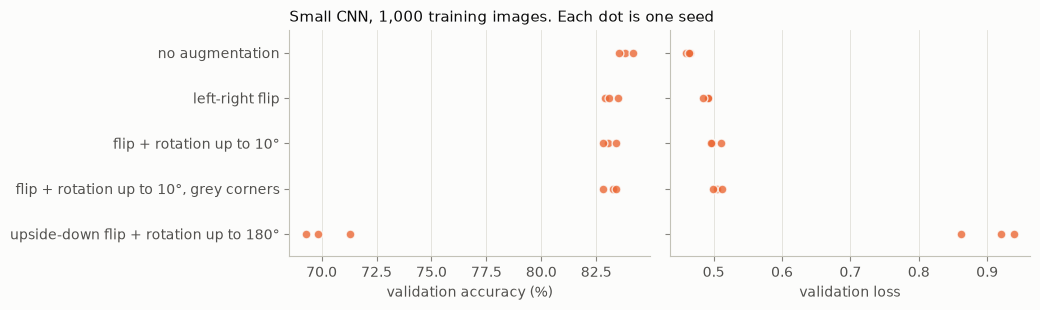

In [40]:
fig, (ax_acc, ax_loss) = plt.subplots(1, 2, figsize=(10.5, 3.2), sharey=True)
names = list(AUGMENT_SETTINGS)
for y_pos, setting in enumerate(names):
    rows = results_augment[results_augment.setting == setting]
    for ax, column, scale in ((ax_acc, "val_accuracy", 100), (ax_loss, "val_loss", 1)):
        ax.scatter(scale * rows[column], [y_pos] * len(rows), s=40, color=VAL_COLOUR, alpha=0.8,
                   edgecolors="#fcfcfb", linewidths=1, zorder=3)
for ax in (ax_acc, ax_loss):
    ax.grid(axis="x")
    ax.set_axisbelow(True)
ax_acc.set_yticks(range(len(names)), names)
ax_acc.set_ylim(len(names) - 0.5, -0.5)
ax_acc.set_xlabel("validation accuracy (%)")
ax_loss.set_xlabel("validation loss")
ax_acc.set_title("Small CNN, 1,000 training images. Each dot is one seed", loc="left")
fig.tight_layout()
plt.show()

**What the seeds show.**

- **No augmentation is best here:** 83.5–84.2% validation accuracy, loss 0.460–0.466. The
  left-right flip costs about 0.7 points (82.9–83.5%, loss 0.485–0.492), and flip + rotation
  about the same, with a slightly higher loss (0.496–0.511). The dots do not overlap, so these
  are real differences, even if small.
- **The grey corners make no measurable difference here:** the dots of the two rotation
  settings lie on top of each other. To tell a shirt from a bag, the model can simply learn to
  ignore the corners. In 5c we see why that is different in anomaly detection.
- **Upside-down + any angle is much worse:** about 70% instead of 84%, and the runs needed more
  than twice as many epochs (96 against 37 on average). From the same 1,000 images, the model has
  to learn every item in every orientation, while the validation images show only one.
- **Why does not even the flip help?** Fashion-MNIST is unusually tidy: every item is centred and
  upright, and almost every shoe points left. Augmentation prepares the model for variation that
  the validation images do not have, and that preparation is not free. This is our result for
  this small CNN and these settings, not a general law; the test below checks the explanation.

**A test of that explanation.** What if the photos the model is used on were *not* tidy, for
example taken by hand: some mirrored, some a little tilted? We change the validation images once,
with a fixed seed so that every model sees the same changed images, and evaluate the seed-42
model of each setting on them. Nothing is trained again. Two changed copies:

- **mirrored**: every validation image flipped left-right;
- **mirrored or not, tilted**: `flip_and_rotate` applied once (half mirrored, all tilted by up
  to 10°).

In [41]:
torch.manual_seed(SEED)
X_val_mirrored = flip(X_val)
X_val_tilted = flip_and_rotate(X_val.to(DEVICE)).cpu()
changed_sets = {"validation images": val_loader,
                "mirrored": make_loader(X_val_mirrored, y_val, shuffle=False),
                "mirrored or not, tilted": make_loader(X_val_tilted, y_val, shuffle=False)}

robustness = pd.DataFrame(
    {name: {setting: evaluate(model, loader)[1] for setting, model in augment_models.items()}
     for name, loader in changed_sets.items()})
robustness.index.name = "trained with (seed 42)"
robustness.to_csv(RESULTS_DIR / "stage1_augmentation_robustness.csv")
(100 * robustness).round(1)  # validation accuracy in %

,validation images,mirrored,"mirrored or not, tilted"
trained with (seed 42),,,
no augmentation,83.8,59.5,69.7
left-right flip,82.9,82.9,80.5
flip + rotation up to 10°,83.0,83.1,82.2
"flip + rotation up to 10°, grey corners",82.8,82.8,82.0
upside-down flip + rotation up to 180°,69.8,68.7,69.4


**What the test shows.**

- **Without augmentation, the model breaks on mirrored images:** 59.5% instead of 83.8%. Among
  other things, it learned that shoes point left. On the tilted set (half of it mirrored) it
  reaches 69.7%.
- **With flip + rotation, it hardly notices:** 83.1% on mirrored and 82.2% on tilted images,
  against 83.0% on the normal ones. The grey-corner version behaves the same.
- **The flip alone protects against exactly what it showed:** 82.9% on mirrored images, but
  80.5% on tilted ones, because it never saw a tilt.
- **Upside-down + any angle** is about equally poor on all three (69–70%): robust to everything,
  good at nothing.
- **So augmentation buys robustness to the changes it shows the model, and it only pays if those
  changes really happen in use.** Here they do not, so we pay up to a point of accuracy for
  nothing. For a
  shop whose photos are taken by hand, the same augmentation would be worth a lot. The question
  to ask is always: *what variation will the model meet in use?*

**And with all 50,000 training images?** With 50 times more real images, there is less to gain.
One run of the section 4 CNN with flip + rotation up to 10°, compared with the run without
augmentation from 4d (same seed, same settings), also tested on the changed validation images.
About 2 minutes.

In [42]:
full_aug_history, full_aug_model, full_aug_summary = run(
    "small CNN + flip + rotation up to 10°", SmallCNN, X_train, y_train, max_epochs=50,
    weight_decay=0.1, patience=5, augment=flip_and_rotate)
print(f"stopped after epoch {full_aug_summary['epochs_trained']}, kept the weights of epoch "
      f"{full_aug_summary['epoch_used']}; training time {full_aug_summary['seconds']:.0f} s")

full_models = {"small CNN (4d)": (cnn_model, cnn_summary),
               "small CNN + flip + rotation up to 10°": (full_aug_model, full_aug_summary)}
augment_full = pd.DataFrame([comparison_row(name, model, summary)
                             for name, (model, summary) in full_models.items()]).set_index("model")
for set_name in ("mirrored", "mirrored or not, tilted"):  # the changed validation images from above
    augment_full[f"val_accuracy {set_name}"] = [evaluate(model, changed_sets[set_name])[1]
                                                for model, _ in full_models.values()]
augment_full.to_csv(RESULTS_DIR / "stage1_augmentation_full_data.csv")
augment_full.drop(columns=["epochs_trained", "seconds_per_epoch"]).T.round(4)

stopped after epoch 30, kept the weights of epoch 25; training time 99 s


model,small CNN (4d),small CNN + flip + rotation up to 10°
parameters,50186.0000,50186.0000
epoch_used,28.0000,25.0000
train_accuracy,0.9625,0.9295
val_accuracy,0.9269,0.9151
val_loss,0.2084,0.2347
training_seconds,100.0934,98.8833
val_accuracy mirrored,0.6963,0.9167
"val_accuracy mirrored or not, tilted",0.7899,0.9104


**On 50,000 images, the picture is the same.** With flip + rotation, the CNN reaches 91.5%
(validation loss 0.235) against 92.7% (0.208) without augmentation, and training took about as
long. On mirrored validation images, the CNN without augmentation drops to 69.6%, while the
augmented one keeps 91.7% (mirrored or not and tilted: 79.0% against 91.0%). More real images
did not make augmentation pay here, because the extra images are just as tidy as the first
1,000.

### 5c. When augmentation is wrong: MVTec AD

In anomaly detection, the training images are all good, and the model learns what "good" looks
like. If an augmentation turns a good image into something that looks like a defect, we teach
the model that this defect is normal, and it will stop finding it. Four examples on good MVTec
AD training images, resized to 256 × 256 as our models will see them. metal_nut is not one of
our five categories, but it shows the problem most clearly.

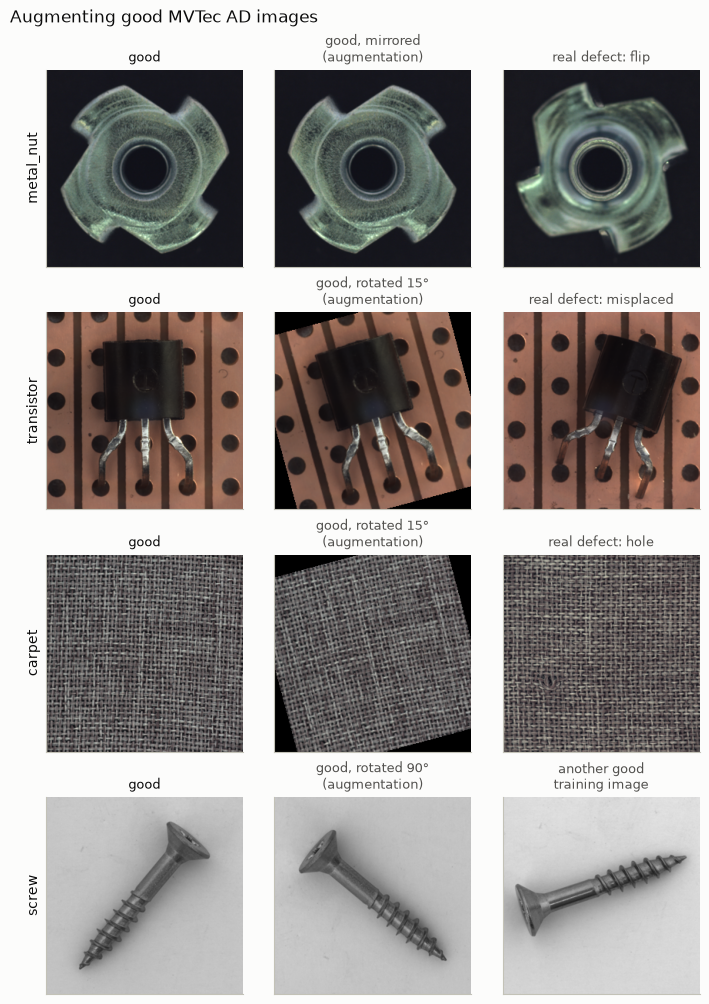

In [43]:
MVTEC_DIR = project_path(config["paths"]["data_dir"])
SIDE = config["image"]["resize"]  # 256, as the models will see them


def load(relative: str) -> Image.Image:
    """One MVTec AD image as RGB, resized like the model input. Only for looking."""
    return Image.open(MVTEC_DIR / relative).convert("RGB").resize((SIDE, SIDE))


nut, transistor, screw = (load(f"{c}/train/good/000.png") for c in ("metal_nut", "transistor", "screw"))
carpet = load("carpet/train/good/000.png")
# Image.rotate fills the corners it uncovers with black; mirror = left-right flip.
mvtec_rows = [
    ("metal_nut", [(nut, "good"), (ImageOps.mirror(nut), "good, mirrored\n(augmentation)"),
                   (load("metal_nut/test/flip/000.png"), "real defect: flip")]),
    ("transistor", [(transistor, "good"),
                    (transistor.rotate(15, resample=Image.BILINEAR), "good, rotated 15°\n(augmentation)"),
                    (load("transistor/test/misplaced/001.png"), "real defect: misplaced")]),
    ("carpet", [(carpet, "good"),
                (carpet.rotate(15, resample=Image.BILINEAR), "good, rotated 15°\n(augmentation)"),
                (load("carpet/test/hole/000.png"), "real defect: hole")]),
    ("screw", [(screw, "good"),
               (screw.rotate(90), "good, rotated 90°\n(augmentation)"),  # 90°: no empty corners
               (load("screw/train/good/001.png"), "another good\ntraining image")]),
]
fig, axes = plt.subplots(len(mvtec_rows), 3, figsize=(7.2, 10.2))
for row, (category, panels) in enumerate(mvtec_rows):
    for col, (image, title) in enumerate(panels):
        ax = axes[row, col]
        ax.imshow(image)
        ax.set_title(title, fontsize=9, color=INK if col == 0 else INK_SECONDARY)
        ax.set_xticks([])
        ax.set_yticks([])
    axes[row, 0].set_ylabel(category, fontsize=10, color=INK)
fig.suptitle("Augmenting good MVTec AD images", x=0.01, ha="left")
fig.tight_layout()
plt.show()


**What the pictures show.**

- **metal_nut:** the `flip` defect is a nut lying upside down. Seen from above, an upside-down
  nut has the mirror image of the normal shape: its tabs turn the other way. A mirrored good nut
  has exactly that shape (only its surface still shows the top side). Train on mirrored nuts,
  and the model learns that this defect is normal.
- **transistor:** in every good image, the transistor stands upright in the same place. Rotated,
  it looks like the `misplaced` defect: a tilted transistor. The black corners are a second
  problem.
- **carpet:** a rotated carpet still looks like carpet in the middle, but the rotation uncovers
  four black corners, and no good carpet has them. A model trained on them learns that dark
  areas at the edge are normal, while a real defect such as this `hole` is much smaller than
  those corners.
- **screw:** the good screws already lie at every angle (compare the third image), so a screw
  rotated by 90° is just another good screw. Here rotation adds nothing that is not already in
  the data, and it may help. (Angles other than 90°, 180° and 270° would again uncover corners.)

**The rule for our five categories,** to apply in Stage 2, where the autoencoder is trained on
good images: use an augmentation only if the good training images already show that kind of
variation. Look at the training images of each category before choosing one. Never rotate or
mirror an object whose position and orientation are fixed, such as the transistor. PatchCore
(Stage 3) is not trained at all, so it needs no augmentation.

## Final check: the test set

Every choice in this notebook (number of epochs, dropout, weight decay, CNN or fully connected,
augmentation or not) was made on the validation set. Because we kept whatever scored best on
those 10,000 images, their validation scores are a little optimistic: part of a model's lead may
be luck that happens to fit exactly these images. The **test set**, 10,000 images we have not
used since 1d, answers the real question: how good is the model on images that played no part in
any decision?

We use it **once**, for the two models we chose: the fully connected network from 3f and the CNN
from 4d. We do not test the other settings, and we change nothing after seeing these numbers;
otherwise the test set would become a second validation set. The test images are scaled with the
mean and standard deviation of the *training* images (2a), like every other image.

In [44]:
X_test, y_test = to_model_input(test_set.data), test_set.targets  # training mean and std (2a)
test_loader = make_loader(X_test, y_test, shuffle=False)

final_models = {"fully connected (3f)": fc_final, "small CNN (4d)": cnn_model}
rows = []
for name, model in final_models.items():
    val_loss, val_accuracy = evaluate(model, val_loader)
    test_loss, test_accuracy = evaluate(model, test_loader)
    rows.append({"model": name, "parameters": count_parameters(model),
                 "val_accuracy": val_accuracy, "test_accuracy": test_accuracy,
                 "val_loss": val_loss, "test_loss": test_loss})
test_results = pd.DataFrame(rows).set_index("model")
test_results.to_csv(RESULTS_DIR / "stage1_test.csv")
print(f"test images: {len(X_test):,}")
test_results.round(4)

test images: 10,000


,parameters,val_accuracy,test_accuracy,val_loss,test_loss
model,,,,,
fully connected (3f),269322,0.8924,0.8862,0.2980,0.3214
small CNN (4d),50186,0.9269,0.9225,0.2084,0.2191


**What the test set shows.**

- **Both models score a little lower on the test set than on validation:** the fully connected
  network 88.6% instead of 89.2%, the CNN 92.3% instead of 92.7% (loss 0.321 instead of 0.298,
  and 0.219 instead of 0.208). That is the small optimism we expected: we kept these models
  because they did well on the validation images.
- **The ranking holds:** the CNN is 3.6 points better on the test set, 3.5 on validation. The
  conclusion of section 4 survives an honest test.
- **These are the final Stage 1 numbers:** 88.6% for the fully connected network and 92.3% for
  the small CNN, on 10,000 images that played no part in any choice. We change nothing after
  seeing them.

## What I learned

### 1. Tensors, gradients and gradient descent

- A **tensor** is a grid of numbers with a shape, a dtype and a device. PyTorch wants images as
  channels × height × width, with the batch as an extra dimension in front: (batch, C, H, W).
- A **gradient** says how much the loss changes when a weight is nudged up. For ŷ = w·x + b with
  w = 1, b = 0, x = 2, y = 7, the loss is 25 and the gradients are −20 (w) and −10 (b). By hand,
  by PyTorch (`loss.backward()`) and by nudging, all three gave the same numbers.
- **Gradient descent** steps against the gradient: weight ← weight − learning rate × gradient.
  Every training loop has the same five steps: forward pass, loss, `zero_grad`, `backward`,
  `step`.
- **The learning rate decides whether training works.** On the line example, 0.01 was too slow,
  0.1 found the best line (w = 2.931, b = 2.000, the same as the exact least-squares formula),
  and 1.05 blew up.
- **My experiment with learning rate 1.0.** At first I got an error and the green line
  disappeared. That came from an old copy of the notebook still open in VS Code, not from the
  learning rate. With the fixed notebook, the loss stopped falling at about 4.7 and then slowly
  grew: b jumped from one side of its best value to the other (its distance was multiplied by
  1 − 2 × 1.0 = −1 at every step) and never settled. 1.0 is right at the limit for this problem.
- **Tool lesson:** after Claude changes a notebook, run *File: Revert File* in VS Code before
  running anything.

### 2. A fully connected network

- Scale the inputs with the mean and standard deviation of the **training** images only, so
  nothing about the validation images leaks into training.
- A **mini-batch** (128 images) gives one update; an **epoch** is one pass over all training
  images (391 updates).
- A **linear layer** computes weighted sums; **ReLU** between layers lets the network bend.
  Without activations, many layers can do no more than one.
- **Softmax** turns the 10 logits into probabilities; **cross-entropy** is −log(probability of
  the true class). An untrained model should start near −log(0.1) = 2.30; mine started at 2.31,
  a quick check that everything is wired correctly.
- The **validation set** is for making choices; the **test set** is used once, at the very end.
- The network (269,322 weights) reached about 89% validation accuracy. After epoch 6 the
  validation loss rose while the accuracy stayed flat: the model was becoming overconfident.
- **Look at the mistakes.** Tops were confused with tops, shoes with shoes, and shirts were
  recognised only 69% of the time. The model was about 100% sure of its worst mistakes, and some
  of those labels look wrong.

### 3. Overfitting

- **Overfitting** means memorising the training images instead of learning what holds for new
  ones. With 1,000 training images: 100% training accuracy, 81% validation accuracy, and the
  validation loss doubled from 0.55 to 1.08.
- **Early stopping** keeps the weights of the epoch with the lowest validation loss. It halved the
  validation loss and saved most of the training time.
- **Dropout** switches off random units during training; **weight decay** shrinks every weight a
  little at each step. Both need the right strength: too strong causes **underfitting** (weight
  decay 10: validation accuracy fell to 78.8%).
- **The fixes cured overconfidence, not accuracy.** Accuracy stayed at about 81% (1,000 images)
  and 89% (50,000 images) whatever I did.
- **The right strength depends on the amount of data.** The setting that helped on 1,000 images
  was too strong on 50,000.
- **Compare against seed noise.** A difference smaller than the spread between seeds is not a
  real difference.

### 4. A small CNN

- A **convolution** slides a small filter over the image; the result, a **feature map**, is large
  where the image looks like the filter. The same few weights are reused at every position.
- **Max pooling** keeps the strongest value in each 2 × 2 block: smaller maps, a little tolerance
  to shifts, and later layers see larger regions of the image.
- With **50,186 weights** the CNN reached **92.7%**, against 89.2% for the fully connected
  network with 269,322. It was better in every class, most of all for shirts (+10 points). Using
  the structure of images beats having more weights.
- The price is compute: about 4 times longer per epoch.
- The first layer learned edge-like filters by itself; the second combines edges into parts.
  Pretrained CNNs (Stage 3) have learned this from millions of images.
- **Padding** can create fake edges at the image border: worth remembering for MVTec defects near
  the edge.

### 5. Data augmentation

- **Data augmentation** changes every training image a little, at random, in every epoch: flip
  it, rotate it. The label must stay the same. Only training images are augmented, never
  validation or test images.
- **Rotation uncovers corners** that must be filled with the background colour. After scaling,
  black is −0.81, not 0: filling with 0 draws grey corners, the same trap as padding in 4a.
- **On Fashion-MNIST, augmentation did not help.** On 1,000 images (3 seeds): 83.9% without,
  83.2% with flips, 83.1% with flips + rotation, 70.1% with upside-down + any angle. On 50,000
  images: 92.7% without, 91.5% with flips + rotation.
- **It buys robustness, not accuracy.** On mirrored validation images, the model without
  augmentation fell from 83.8% to 59.5%; the augmented one kept 83.1%. Augmentation only pays if
  the changes it shows really happen in use, and Fashion-MNIST photos are all tidy.
- **In anomaly detection the rule is stricter:** every training image is "good", so an
  augmentation must never create something that looks like a defect. A mirrored metal nut has
  the shape of the `flip` defect; a rotated transistor looks `misplaced`. Only use variation the
  good training images already show (a rotated screw is fine).

### Final check on the test set

- The test set is used **once**, at the end, for the models chosen on validation. Fully
  connected: 88.6% (validation 89.2%); small CNN: 92.3% (validation 92.7%). Both a little lower,
  because we chose them for their validation scores; the CNN's lead held (3.6 points).

### Check yourself

1. Why must `optimizer.zero_grad()` be called before `loss.backward()`?
2. What loss should an untrained 10-class model have, and why?
3. The validation loss rises but the validation accuracy stays flat. What is happening?
4. Why does a CNN need fewer weights than a fully connected network for the same image?
5. Why may the test set not be used to choose the number of epochs?
6. Why is rotation a reasonable augmentation for screw images but a wrong one for transistor images?

### My own notes

- 